# Notebook 00: Data overview, cleaning check and EDA (all 9 datasets)

**Project:** AI-Optimized Trim & Fuse for Derivative Chips (MCU, PMIC, sensor, SoC)

**Purpose of this notebook:** look at every dataset before any modelling.
For each of the 9 files we:
1. load it and explain what it is
2. check data quality: types, missing values, duplicates
3. decide **whether cleaning is needed**, and clean only if it is
4. run EDA (charts) where it makes sense
5. save a cleaned copy for the modelling notebooks

| # | Dataset | Chip | Used next in |
|---|---|---|---|
| 1 | `mcu_trim_fuse.csv` | MCU | 01 MCU |
| 2 | `mcu_fuse_schema.csv` | MCU | 01 MCU |
| 3 | `mcu_fuse_map_audit.csv` | MCU | 01 MCU |
| 4 | `pmic_trim_otp.csv` | PMIC | 02 PMIC |
| 5 | `pmic_otp_config_requests.csv` | PMIC | 02 PMIC |
| 6 | `sensor_calibration.csv` | Sensor | 03 Sensor |
| 7 | `soc_binning_harvesting.csv` | SoC | 04 SoC |
| 8 | `soc_sku_demand.csv` | SoC | 04 SoC |
| 9 | `memory_repair_bitmaps.csv` | SoC memory | 04 SoC |

**No models are trained here.** Training happens in notebooks 01 to 04.

**How to run in Colab:** Runtime → Run all. When the upload box appears, upload either the dataset **zip** or the 9 CSV files.

## 0.1 Setup
Libraries, and three helper functions used for every dataset:
- `quality_check()`: types, missing values, duplicates
- `text_columns()`: lists columns stored as text (these may need converting)
- `wafer_map()`: plots dies at their real position on the wafer

In [1]:
import os, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
clean = []  # datasets that get a cleaned copy


def text_columns(df):
    return df.select_dtypes(exclude=["number", "bool"]).columns.tolist()


def quality_check(df, name, id_col=None):
    print(f"===== {name} =====")
    print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
    kinds = {"numeric": df.select_dtypes("number").shape[1], "boolean": df.select_dtypes("bool").shape[1],
             "text": len(text_columns(df))}
    print("Column types:", kinds)
    na = df.isna().sum()
    na = na[na > 0]
    print("Missing values:", "none" if na.empty else "")
    if not na.empty:
        print((pd.DataFrame({"missing": na, "pct": (na / len(df) * 100).round(2)})).to_string())
    print("Duplicate rows:", int(df.duplicated().sum()))
    if id_col:
        print(f"Duplicate {id_col}:", int(df[id_col].duplicated().sum()))
    if text_columns(df):
        print("Text columns:", text_columns(df))


def wafer_map(df, col, title, ax, cmap="viridis"):
    w = df.wafer_id.iloc[0] if "wafer_id" in df else ""
    one = df[df.wafer_id == w]
    sc = ax.scatter(one.x_mm, one.y_mm, c=one[col], cmap=cmap, s=22, marker="s")
    plt.colorbar(sc, ax=ax)
    ax.set_title(f"{title}\n(wafer {w})")
    ax.set_aspect("equal")

print("Setup done")

Setup done


## 0.2 Find or upload the 9 files
Searches the current folder and its subfolders. In Colab, if any file is missing, an upload box appears; a **zip** is extracted automatically.

In [2]:
FILES = ["mcu_trim_fuse.csv", "mcu_fuse_schema.csv", "mcu_fuse_map_audit.csv",
         "pmic_trim_otp.csv", "pmic_otp_config_requests.csv", "sensor_calibration.csv",
         "soc_binning_harvesting.csv", "soc_sku_demand.csv", "memory_repair_bitmaps.csv"]


def find(name):
    hits = [h for h in glob.glob(f"**/{name}", recursive=True) if "cleaned" not in h]
    return min(hits, key=len) if hits else None


missing = [f for f in FILES if find(f) is None]
if missing:
    try:
        from google.colab import files
        print("Missing:", missing, "\nUpload the dataset zip or the CSV files:")
        for fname in files.upload():
            if fname.lower().endswith(".zip"):
                zipfile.ZipFile(fname).extractall("dataset_upload")
    except ImportError:
        raise FileNotFoundError(f"Put these files next to the notebook: {missing}")

PATHS = {f: find(f) for f in FILES}
still_missing = [f for f, p in PATHS.items() if p is None]
assert not still_missing, f"Still missing: {still_missing}"
for f, p in PATHS.items():
    print(f"{f:32s} -> {p}")

mcu_trim_fuse.csv                -> mcu_trim_fuse.csv
mcu_fuse_schema.csv              -> mcu_fuse_schema.csv
mcu_fuse_map_audit.csv           -> mcu_fuse_map_audit.csv
pmic_trim_otp.csv                -> pmic_trim_otp.csv
pmic_otp_config_requests.csv     -> pmic_otp_config_requests.csv
sensor_calibration.csv           -> sensor_calibration.csv
soc_binning_harvesting.csv       -> soc_binning_harvesting.csv
soc_sku_demand.csv               -> soc_sku_demand.csv
memory_repair_bitmaps.csv        -> memory_repair_bitmaps.csv


## 0.3 Load all 9 datasets
Each file goes into a dictionary `raw` under a short name.

In [3]:
SHORT = {"mcu_trim_fuse.csv": "mcu", "mcu_fuse_schema.csv": "schema", "mcu_fuse_map_audit.csv": "audit",
         "pmic_trim_otp.csv": "pmic", "pmic_otp_config_requests.csv": "otp_req",
         "sensor_calibration.csv": "sensor", "soc_binning_harvesting.csv": "soc",
         "soc_sku_demand.csv": "sku", "memory_repair_bitmaps.csv": "repair"}
raw = {SHORT[f]: pd.read_csv(p) for f, p in PATHS.items()}
print("Loaded:", list(raw))

Loaded: ['mcu', 'schema', 'audit', 'pmic', 'otp_req', 'sensor', 'soc', 'sku', 'repair']


## 0.4 Overview of all 9 datasets
One row per dataset: size, chip type, what it is for, and a first data-quality count.

In [4]:
INFO = {
    "mcu":     ("MCU",    "Trim codes (bandgap, oscillator, LDO), drift, pass/fail, fuse maps", "regression / classification"),
    "schema":  ("MCU",    "Bit layout of the 64-bit MCU fuse word", "reference table"),
    "audit":   ("MCU",    "Fuse words, 25% with injected errors", "rule-based validation"),
    "pmic":    ("PMIC",   "Reference + 4 rail trims, thresholds, current sense, OTP image", "regression"),
    "otp_req": ("PMIC",   "Customer OTP configuration requests", "rule check / classification"),
    "sensor":  ("Sensor", "Accelerometer calibration at -40/25/85 C", "regression"),
    "soc":     ("SoC",    "Per-core Fmax/Vmin/defects, AVS bin, SKU", "regression + optimization"),
    "sku":     ("SoC",    "SKU specs, prices and weekly demand", "optimizer input"),
    "repair":  ("SoC",    "Memory fail bitmaps, greedy vs exact repair", "optimization"),
}
overview = pd.DataFrame([{
    "dataset": k, "chip": INFO[k][0], "rows": len(d), "columns": d.shape[1],
    "missing_cells": int(d.isna().sum().sum()), "duplicate_rows": int(d.duplicated().sum()),
    "text_columns": len(text_columns(d)), "content": INFO[k][1], "task_type": INFO[k][2]}
    for k, d in raw.items()])
overview

,dataset,chip,rows,columns,missing_cells,duplicate_rows,text_columns,content,task_type
0,mcu,MCU,8420,42,0,0,7,"Trim codes (bandgap, oscillator, LDO), drift, ...",regression / classification
1,schema,MCU,10,7,0,0,5,Bit layout of the 64-bit MCU fuse word,reference table
2,audit,MCU,1500,5,0,0,4,"Fuse words, 25% with injected errors",rule-based validation
3,pmic,PMIC,11060,63,0,0,8,"Reference + 4 rail trims, thresholds, current ...",regression
4,otp_req,PMIC,400,10,0,0,6,Customer OTP configuration requests,rule check / classification
5,sensor,Sensor,11060,67,0,0,5,Accelerometer calibration at -40/25/85 C,regression
6,soc,SoC,6160,52,10668,0,6,"Per-core Fmax/Vmin/defects, AVS bin, SKU",regression + optimization
7,sku,SoC,3,6,0,0,1,"SKU specs, prices and weekly demand",optimizer input
8,repair,SoC,3000,13,3526,0,6,"Memory fail bitmaps, greedy vs exact repair",optimization


**First look:**
- No dataset has duplicate rows.
- Only **2 datasets** have missing values (SoC and memory repair). Below we check whether those blanks are errors or meaningful.
- Several datasets store values as **text** (hex numbers, sequences, lists). Those are the real cleaning work.

---
# 1. `mcu_trim_fuse.csv`: MCU trims (main dataset)
Each row is one MCU die: process data, untrimmed readings, the best trim codes, values after packaging, pass/fail and the fuse word.
Notebook 01 already has a full EDA and models for this file, so here we cover quality plus the key charts.

## 1.1 Preview and quality check

In [5]:
mcu = raw["mcu"].copy()
quality_check(mcu, "mcu_trim_fuse", "die_id")
mcu.head(3)

===== mcu_trim_fuse =====
Rows: 8,420 | Columns: 42
Column types: {'numeric': 30, 'boolean': 5, 'text': 7}
Missing values: none
Duplicate rows: 0
Duplicate die_id: 0
Text columns: ['die_id', 'lot_id', 'wafer_id', 'derivative', 'package', 'temp_grade', 'fuse_map_hex']


,die_id,lot_id,wafer_id,derivative,die_x,die_y,x_mm,y_mm,radius_mm,pcm_vth_n_mV,pcm_vth_p_mV,pcm_rs_ohm_sq,pcm_tox_A,pcm_mobility_rel,package,temp_grade,latent_defect,bg_untrim_V,bg_trim_code_opt,bg_trimmed_sort_V,bg_conv_iterations,hsi_untrim_MHz,hsi_trim_code_opt,hsi_trimmed_sort_MHz,hsi_conv_iterations,ldo_untrim_V,ldo_trim_code_opt,ldo_trimmed_sort_V,ldo_conv_iterations,ts_cal1_30C_counts,ts_slope_counts_per_C_true,ts_cal2_110C_counts,ts_cal2_measured_on_tester,sram_fail_bits,sram_repairable,conv_trim_time_ms,sort_pass,bg_final_V,hsi_final_MHz,ldo_final_V,final_pass,fuse_map_hex
0,MCU-000000,MA1,MA1-W01,MCU-A,9,1,-24.0,-88.0,91.21,452.04,-477.49,284.88,20.435,1.0356,QFN48,industrial,False,1.19017,37,1.20051,6,16.98648,36,16.04461,7,1.09439,17,1.09872,7,1055,3.2525,1316,False,0,True,28.2,True,1.20278,15.99442,1.10050,True,0x000002FF507E2925
1,MCU-000001,MA1,MA1-W01,MCU-A,10,1,-16.0,-88.0,89.44,434.45,-489.77,283.29,20.743,1.0051,QFN48,industrial,False,1.17902,43,1.20058,6,17.09167,34,15.99064,9,1.08332,20,1.10155,5,1036,3.2709,1299,False,0,True,30.2,True,1.20148,15.97626,1.10505,True,0x000002FF503288AB
2,MCU-000002,MA1,MA1-W01,MCU-A,11,1,-8.0,-88.0,88.36,440.99,-478.68,278.32,20.573,1.0356,QFN48,industrial,False,1.18039,42,1.20093,6,16.91557,36,15.99795,7,1.09265,17,1.09795,5,1037,3.2503,1295,False,1,True,26.2,True,1.20278,15.94578,1.09791,True,0x000002FF5036292A


## 1.2 Is cleaning needed?
- Missing values: none. Duplicates: none.
- Text columns: IDs (`die_id`, `lot_id`, `wafer_id`), categories (`derivative`, `package`, `temp_grade`) and `fuse_map_hex`.
- **Needed:** convert `fuse_map_hex` into a number and decode its fields, so we can confirm the fuse word matches the trim codes. This is a consistency check.

In [6]:
mcu["fuse_word"] = mcu.fuse_map_hex.apply(lambda h: int(h, 16)).astype("int64")  # 43 bits used, fits int64
mcu["fuse_bg"] = mcu.fuse_word % 2**6                # bits 0-5
mcu["fuse_hsi"] = (mcu.fuse_word // 2**6) % 2**7     # bits 6-12
mcu["fuse_ldo"] = (mcu.fuse_word // 2**13) % 2**5    # bits 13-17
ok = ((mcu.fuse_bg == mcu.bg_trim_code_opt) & (mcu.fuse_hsi == mcu.hsi_trim_code_opt)
      & (mcu.fuse_ldo == mcu.ldo_trim_code_opt))
print(f"Fuse word trim fields match the trim-code columns: {ok.mean():.1%} of dies")
mcu = mcu.drop(columns=["fuse_bg", "fuse_hsi", "fuse_ldo"])
for c in ["derivative", "package", "temp_grade"]:
    mcu[c] = mcu[c].astype("category")
clean.append("mcu")

Fuse word trim fields match the trim-code columns: 100.0% of dies


## 1.3 EDA: dies per derivative and the three targets
MCU-A is the large base product; MCU-B and MCU-C are small derivatives.

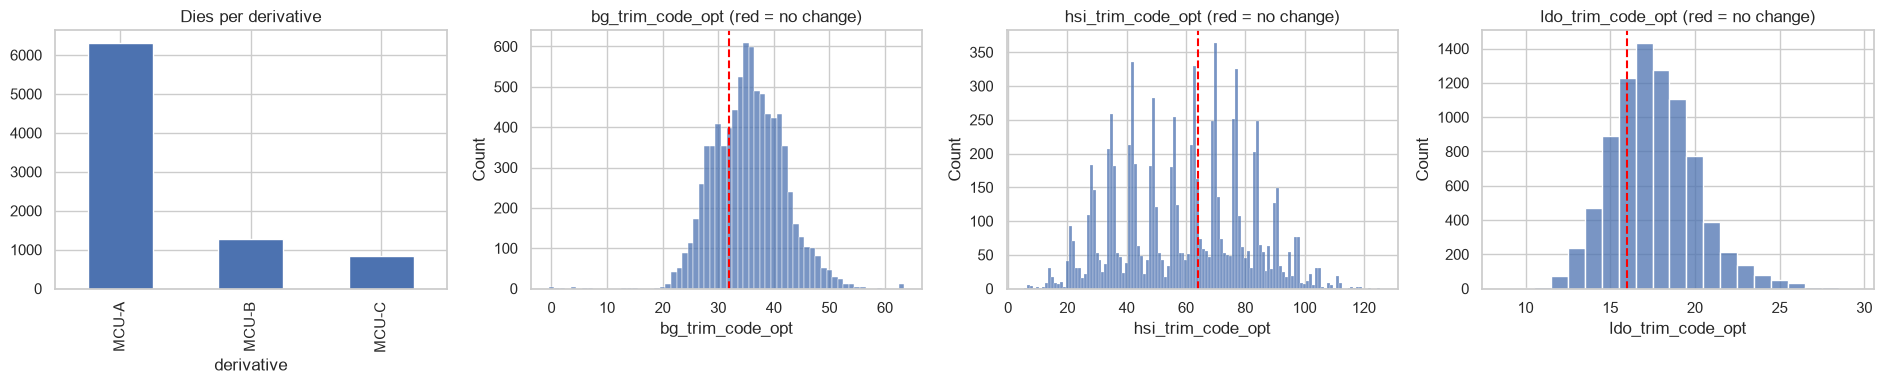

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
mcu.derivative.value_counts().plot.bar(ax=ax[0], color="#4c72b0", title="Dies per derivative")
for a, (col, mid) in zip(ax[1:], [("bg_trim_code_opt", 32), ("hsi_trim_code_opt", 64), ("ldo_trim_code_opt", 16)]):
    sns.histplot(mcu[col], discrete=True, ax=a)
    a.axvline(mid, color="red", ls="--")
    a.set_title(f"{col} (red = no change)")
plt.tight_layout(); plt.show()

## 1.4 EDA: untrimmed reading vs. trim code, and a wafer map
A near-straight line means the untrimmed reading is the strongest predictor. The wafer map shows codes change with position.

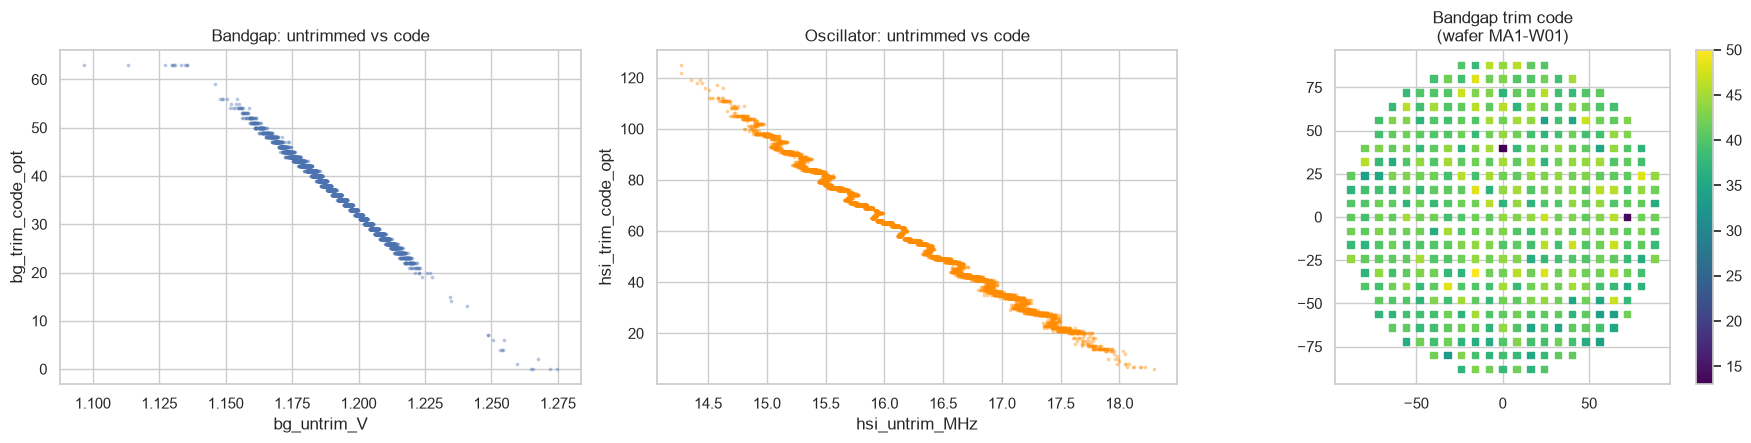

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].scatter(mcu.bg_untrim_V, mcu.bg_trim_code_opt, s=3, alpha=0.3)
ax[0].set(xlabel="bg_untrim_V", ylabel="bg_trim_code_opt", title="Bandgap: untrimmed vs code")
ax[1].scatter(mcu.hsi_untrim_MHz, mcu.hsi_trim_code_opt, s=3, alpha=0.3, color="darkorange")
ax[1].set(xlabel="hsi_untrim_MHz", ylabel="hsi_trim_code_opt", title="Oscillator: untrimmed vs code")
wafer_map(mcu, "bg_trim_code_opt", "Bandgap trim code", ax[2])
plt.tight_layout(); plt.show()

## 1.5 EDA: drift after packaging and pass rates

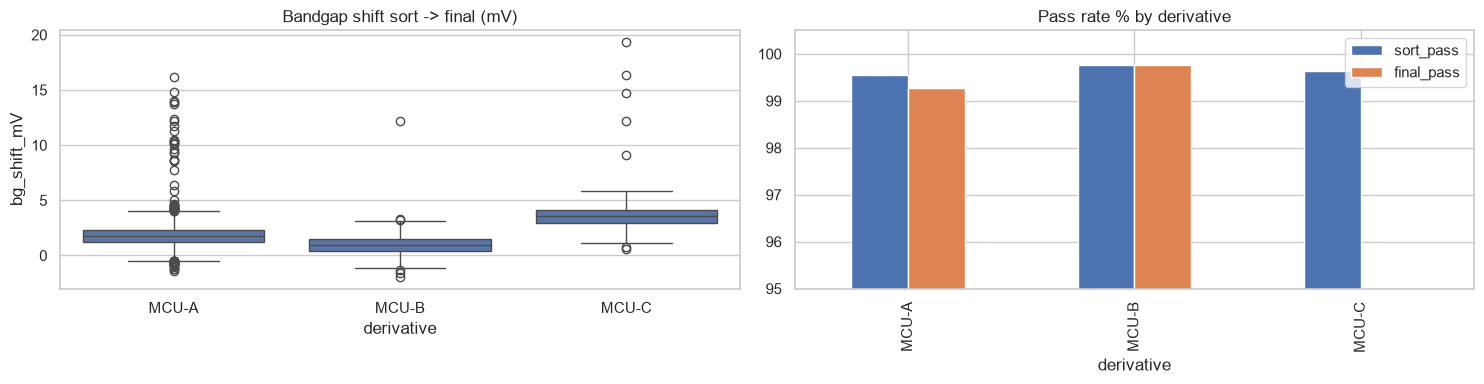

            sort_pass  final_pass
derivative                       
MCU-A           99.56       99.27
MCU-B           99.76       99.76
MCU-C           99.64       90.62


In [9]:
mcu["bg_shift_mV"] = (mcu.bg_final_V - mcu.bg_trimmed_sort_V) * 1000
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=mcu, x="derivative", y="bg_shift_mV", ax=ax[0])
ax[0].set_title("Bandgap shift sort -> final (mV)")
rates = mcu.groupby("derivative", observed=True)[["sort_pass", "final_pass"]].mean() * 100
rates.plot.bar(ax=ax[1], ylim=(95, 100.5), title="Pass rate % by derivative")
plt.tight_layout(); plt.show()
print(rates.round(2).to_string())

**MCU summary:** clean data, and the fuse words agree with the trim codes. The untrimmed reading drives each code. MCU-C drifts most after packaging. Main target for notebook 01: `bg_trim_code_opt`.

---
# 2. `mcu_fuse_schema.csv`: fuse word layout (reference table)
Only 10 rows: one per field in the 64-bit fuse word, with the expected value for each derivative. **No EDA:** this is a lookup table. We display it and draw the bit layout.

In [10]:
schema = raw["schema"].copy()
quality_check(schema, "mcu_fuse_schema")
schema

===== mcu_fuse_schema =====
Rows: 10 | Columns: 7
Column types: {'numeric': 2, 'boolean': 0, 'text': 5}
Missing values: none
Duplicate rows: 0
Text columns: ['field', 'description', 'MCU-A', 'MCU-B', 'MCU-C']


,field,lsb,nbits,description,MCU-A,MCU-B,MCU-C
0,BG_TRIM,0,6,"Bandgap trim code (2 mV/LSB, 32 = no change)",per-die,per-die,per-die
1,HSI_TRIM,6,7,"HSI oscillator trim code (0.2 %/LSB, 64 = no c...",per-die,per-die,per-die
2,LDO_TRIM,13,5,"LDO trim code (5 mV/LSB, 16 = no change)",per-die,per-die,per-die
3,TS_CAL1,18,12,Temperature sensor reading at 30 C,per-die,per-die,per-die
4,FLASH_SIZE,30,2,"0=256 KB, 1=512 KB, 2=1 MB",1,0,2
5,PERIPH_EN,32,8,Peripheral enable mask,0xFF,0x3F,0xFF
6,TEMP_GRADE,40,1,1 = automotive grade,0,0,1
7,DEBUG_LOCK,41,1,1 = debug port locked (required in production),1,1,1
8,RDP,42,1,1 = read-out protection enabled,0,0,1
9,RESERVED,43,21,"Reserved, must be 0",0,0,0


## 2.1 Is cleaning needed?
The derivative columns mix text (`per-die`), hex (`0xFF`) and numbers stored as text.
**Needed:** convert fixed values into numbers (`per-die` stays blank because it differs per die), so a validator can compare against them later.

In [11]:
def to_int(v):
    v = str(v)
    return np.nan if v == "per-die" else int(v, 16) if v.startswith("0x") else int(v)

for d in ["MCU-A", "MCU-B", "MCU-C"]:
    schema[f"{d}_expected"] = schema[d].apply(to_int)
schema["msb"] = schema.lsb + schema.nbits - 1
print("Bits used:", int(schema.nbits.sum()), "of 64")
clean.append("schema")
schema[["field", "lsb", "msb", "nbits", "MCU-A_expected", "MCU-B_expected", "MCU-C_expected"]]

Bits used: 64 of 64


,field,lsb,msb,nbits,MCU-A_expected,MCU-B_expected,MCU-C_expected
0,BG_TRIM,0,5,6,NaN,NaN,NaN
1,HSI_TRIM,6,12,7,NaN,NaN,NaN
2,LDO_TRIM,13,17,5,NaN,NaN,NaN
3,TS_CAL1,18,29,12,NaN,NaN,NaN
4,FLASH_SIZE,30,31,2,1.0,0.0,2.0
5,PERIPH_EN,32,39,8,255.0,63.0,255.0
6,TEMP_GRADE,40,40,1,0.0,0.0,1.0
7,DEBUG_LOCK,41,41,1,1.0,1.0,1.0
8,RDP,42,42,1,0.0,0.0,1.0
9,RESERVED,43,63,21,0.0,0.0,0.0


## 2.2 Picture of the 64-bit fuse word

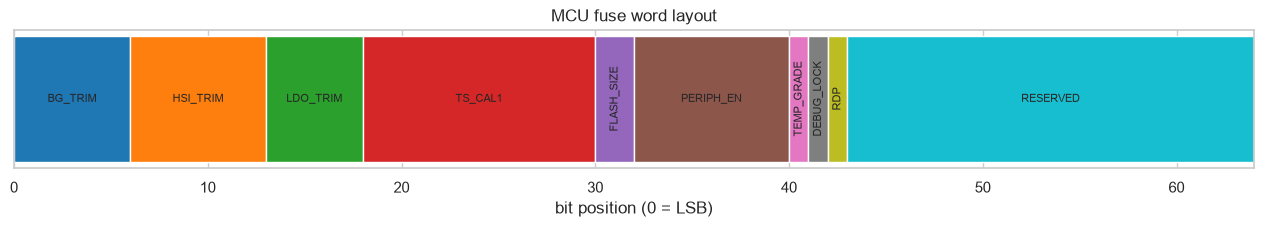

In [12]:
fig, ax = plt.subplots(figsize=(16, 1.8))
colors = sns.color_palette("tab10", len(schema))
for (_, r), c in zip(schema.iterrows(), colors):
    ax.barh(0, r.nbits, left=r.lsb, color=c, edgecolor="white")
    ax.text(r.lsb + r.nbits / 2, 0, r.field, ha="center", va="center", fontsize=8, rotation=90 if r.nbits < 4 else 0)
ax.set_xlim(0, 64); ax.set_yticks([]); ax.set_xlabel("bit position (0 = LSB)")
ax.set_title("MCU fuse word layout"); plt.show()

---
# 3. `mcu_fuse_map_audit.csv`: fuse words with injected errors
1,500 fuse words. 25% contain one deliberate error. Notebook 01 will build a rule-based validator that must catch them.

## 3.1 Preview and quality check

In [13]:
audit = raw["audit"].copy()
quality_check(audit, "mcu_fuse_map_audit", "die_id")
print("All audit dies exist in mcu_trim_fuse:", audit.die_id.isin(mcu.die_id).all())
audit.head()

===== mcu_fuse_map_audit =====
Rows: 1,500 | Columns: 5
Column types: {'numeric': 0, 'boolean': 1, 'text': 4}
Missing values: none
Duplicate rows: 0
Duplicate die_id: 0
Text columns: ['die_id', 'derivative', 'fuse_map_hex', 'error_type']


All audit dies exist in mcu_trim_fuse: True


,die_id,derivative,fuse_map_hex,has_error,error_type
0,MCU-000691,MCU-A,0x000002FF504A2927,False,none
1,MCU-001729,MCU-A,0x000002FF50226C25,False,none
2,MCU-008283,MCU-C,0x000007FF9095F21B,False,none
3,MCU-004616,MCU-A,0x000002FF90065364,True,wrong_flash_size
4,MCU-000612,MCU-A,0x000002FF505DE927,False,none


## 3.2 Is cleaning needed?
No missing values and no duplicates. **Needed:** decode the hex word into its fields with the schema, so each rule can be checked as a column.

In [14]:
def decode_fuse(hex_series):
    w = hex_series.apply(lambda h: int(h, 16))
    out = pd.DataFrame(index=hex_series.index)
    for _, r in schema.iterrows():
        out[r.field] = w.apply(lambda x: (x >> int(r.lsb)) & ((1 << int(r.nbits)) - 1))
    return out

audit = pd.concat([audit, decode_fuse(audit.fuse_map_hex)], axis=1)
clean.append("audit")
audit.head()

,die_id,derivative,fuse_map_hex,has_error,error_type,BG_TRIM,HSI_TRIM,LDO_TRIM,TS_CAL1,FLASH_SIZE,PERIPH_EN,TEMP_GRADE,DEBUG_LOCK,RDP,RESERVED
0,MCU-000691,MCU-A,0x000002FF504A2927,False,none,39,36,17,1042,1,255,0,1,0,0
1,MCU-001729,MCU-A,0x000002FF50226C25,False,none,37,48,19,1032,1,255,0,1,0,0
2,MCU-008283,MCU-C,0x000007FF9095F21B,False,none,27,72,15,1061,2,255,1,1,1,0
3,MCU-004616,MCU-A,0x000002FF90065364,True,wrong_flash_size,36,77,18,1025,2,255,0,1,0,0
4,MCU-000612,MCU-A,0x000002FF505DE927,False,none,39,36,15,1047,1,255,0,1,0,0


## 3.3 EDA: error types and simple rule checks
The crosstab shows that each error type breaks a specific rule, which tells us a rule-based validator should catch them.

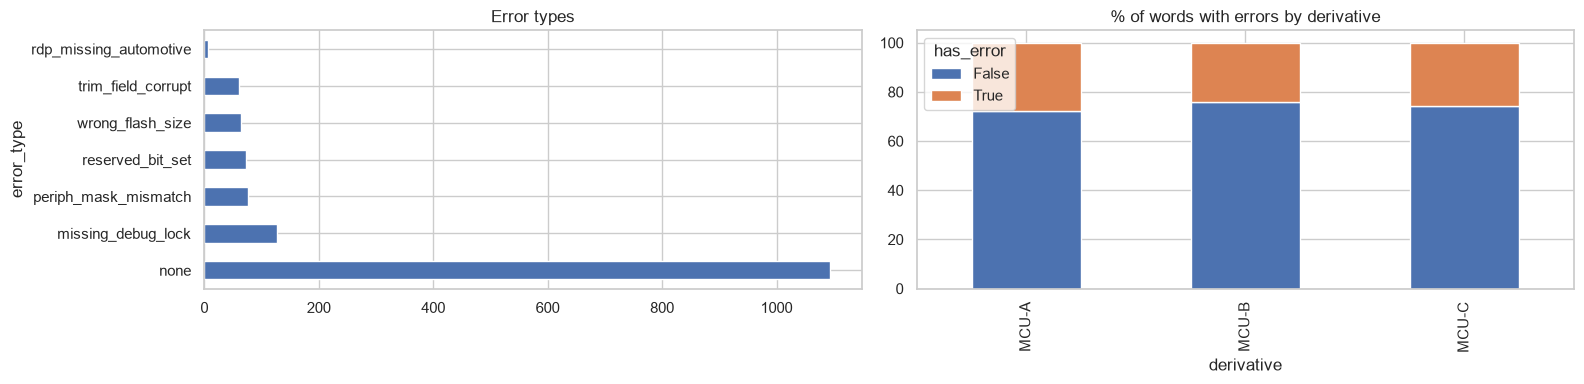

col_0                   debug_unlocked  flash_wrong  no rule broken  periph_wrong  rdp_wrong  reserved_set  trim_mismatch
error_type                                                                                                               
missing_debug_lock                 127            0               0             0          0             0              0
none                                 0            0            1094             0          0             0              0
periph_mask_mismatch                 0            0               0            76          0             0              0
rdp_missing_automotive               0            0               0             0          6             0              0
reserved_bit_set                     0            0               0             0          0            72              0
trim_field_corrupt                   0            0               0             0          0             0             61
wrong_flash_size        

In [15]:
exp = schema.set_index("field")[["MCU-A_expected", "MCU-B_expected", "MCU-C_expected"]]
expect = lambda f: audit.derivative.map(lambda d: exp.loc[f, f"{d}_expected"])
trims = audit.merge(mcu[["die_id", "bg_trim_code_opt", "hsi_trim_code_opt", "ldo_trim_code_opt"]], on="die_id")
rules = pd.DataFrame({
    "flash_wrong": audit.FLASH_SIZE != expect("FLASH_SIZE"),
    "periph_wrong": audit.PERIPH_EN != expect("PERIPH_EN"),
    "debug_unlocked": audit.DEBUG_LOCK != 1,
    "rdp_wrong": audit.RDP != expect("RDP"),
    "reserved_set": audit.RESERVED != 0,
    "trim_mismatch": ((trims.BG_TRIM != trims.bg_trim_code_opt) | (trims.HSI_TRIM != trims.hsi_trim_code_opt)
                      | (trims.LDO_TRIM != trims.ldo_trim_code_opt)).values,
})
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
audit.error_type.value_counts().plot.barh(ax=ax[0], title="Error types")
pd.crosstab(audit.derivative, audit.has_error, normalize="index").mul(100).plot.bar(
    stacked=True, ax=ax[1], title="% of words with errors by derivative")
plt.tight_layout(); plt.show()
print(pd.crosstab(audit.error_type, rules.idxmax(axis=1).where(rules.any(axis=1), "no rule broken")).to_string())

---
# 4. `pmic_trim_otp.csv`: PMIC trims
Each row is one power-management chip: a reference voltage plus 4 output rails (buck1, buck2, ldo1, ldo2), protection thresholds (OVP, UVLO, current limit), current-sense calibration and the OTP image.

## 4.1 Preview and quality check

In [16]:
pmic = raw["pmic"].copy()
quality_check(pmic, "pmic_trim_otp", "die_id")
pmic.head(3)

===== pmic_trim_otp =====
Rows: 11,060 | Columns: 63
Column types: {'numeric': 52, 'boolean': 3, 'text': 8}
Missing values: none
Duplicate rows: 0
Duplicate die_id: 0
Text columns: ['die_id', 'lot_id', 'wafer_id', 'derivative', 'package', 'sequence', 'i2c_addr', 'otp_image_hex']


,die_id,lot_id,wafer_id,derivative,die_x,die_y,x_mm,y_mm,radius_mm,pcm_vth_n_mV,pcm_vth_p_mV,pcm_rs_ohm_sq,pcm_tox_A,pcm_mobility_rel,package,latent_defect,vref_untrim_V,vref_trim_code_opt,vref_trimmed_sort_V,vref_final_V,buck1_target_V,buck1_untrim_V,buck1_trim_code_opt,buck1_trimmed_sort_V,buck1_final_V,buck2_target_V,buck2_untrim_V,buck2_trim_code_opt,buck2_trimmed_sort_V,buck2_final_V,ldo1_target_V,ldo1_untrim_V,ldo1_trim_code_opt,ldo1_trimmed_sort_V,ldo1_final_V,ldo2_target_V,ldo2_untrim_V,ldo2_trim_code_opt,ldo2_trimmed_sort_V,ldo2_final_V,ovp_untrim_V,ovp_trim_code_opt,ovp_trimmed_V,uvlo_untrim_V,uvlo_trim_code_opt,uvlo_trimmed_V,ilim_untrim_A,ilim_trim_code_opt,ilim_trimmed_A,cs_meas_0p5A_A,cs_meas_2p0A_A,cs_gain_err_true_pct,cs_offset_true_mA,cs_inl_true_pct,efficiency_1A_pct,load_reg_mV,conv_trim_iterations,conv_trim_time_ms,sort_pass,final_pass,sequence,i2c_addr,otp_image_hex
0,PMIC-000000,PA1,PA1-W01,PMIC-P1,12,1,-14.0,-91.0,92.07,450.41,-471.02,300.45,20.110,1.0212,WLCSP,False,0.59825,35,0.60041,0.60036,0.8,0.80195,31,0.80016,0.80051,1.1,1.10064,32,1.10075,1.10216,1.8,1.79868,33,1.80125,1.80408,3.3,3.29318,33,3.29744,3.30569,3.6125,9,3.6306,2.6932,9,2.7067,2.9329,18,2.9916,0.50103,1.99939,-0.0918,-1.149,0.0367,90.958,5.280,47,37.6,True,True,buck1>buck2>ldo1>ldo2,0x60,0x00307274381C104A6618607E3
1,PMIC-000001,PA1,PA1-W01,PMIC-P1,13,1,-7.0,-91.0,91.27,444.09,-453.33,288.98,20.072,0.9767,WLCSP,False,0.59456,39,0.60004,0.60012,0.8,0.79885,33,0.79989,0.79927,1.1,1.09065,36,1.10022,1.10089,1.8,1.78156,37,1.80012,1.80054,3.3,3.27264,36,3.30216,3.30627,3.5409,13,3.6294,2.7153,7,2.7017,2.9493,18,3.0083,0.49626,1.99873,0.1437,-5.490,-0.0674,91.865,5.337,44,35.2,True,True,buck1>buck2>ldo1>ldo2,0x60,0x00307274381C1049F64964867
2,PMIC-000002,PA1,PA1-W01,PMIC-P1,14,1,0.0,-91.0,91.00,441.18,-466.24,287.62,20.233,1.0051,WLCSP,False,0.59504,39,0.59996,0.60042,0.8,0.79592,35,0.80073,0.80054,1.1,1.09112,36,1.09973,1.10095,1.8,1.79678,33,1.79874,1.80129,3.3,3.28963,34,3.30043,3.30870,3.5656,12,3.6369,2.7126,7,2.6990,2.8152,23,3.0123,0.49384,1.99119,-0.2393,-4.035,-0.0125,91.295,5.185,45,36.0,True,True,buck1>buck2>ldo1>ldo2,0x60,0x00307274381C105DF228648E7


## 4.2 Is cleaning needed?
No missing values and no duplicates. Text columns that need converting:
- `i2c_addr` (hex text) → number
- `sequence` ("buck1>buck2>ldo1>ldo2") → the power-up position of each rail
- `otp_image_hex` stays as text: it is a 104-bit image, too long for a normal integer column, and it is an output, not a feature.

In [17]:
RAILS = ["buck1", "buck2", "ldo1", "ldo2"]
pmic["i2c_addr_int"] = pmic.i2c_addr.apply(lambda h: int(h, 16))
for r in RAILS:
    pmic[f"seq_pos_{r}"] = pmic.sequence.apply(lambda s: s.split(">").index(r) + 1)
for c in ["derivative", "package"]:
    pmic[c] = pmic[c].astype("category")
clean.append("pmic")
pmic[["derivative", "i2c_addr", "i2c_addr_int", "sequence"] + [f"seq_pos_{r}" for r in RAILS]].drop_duplicates("derivative")

,derivative,i2c_addr,i2c_addr_int,sequence,seq_pos_buck1,seq_pos_buck2,seq_pos_ldo1,seq_pos_ldo2
0,PMIC-P1,0x60,96,buck1>buck2>ldo1>ldo2,1,2,3,4
8295,PMIC-P2,0x61,97,buck2>buck1>ldo1>ldo2,2,1,3,4
9954,PMIC-C7,0x62,98,buck1>ldo1>buck2>ldo2,1,3,2,4


## 4.3 EDA: derivatives and how far each rail starts from its target
Error before trim, as a percentage of the rail's target voltage.

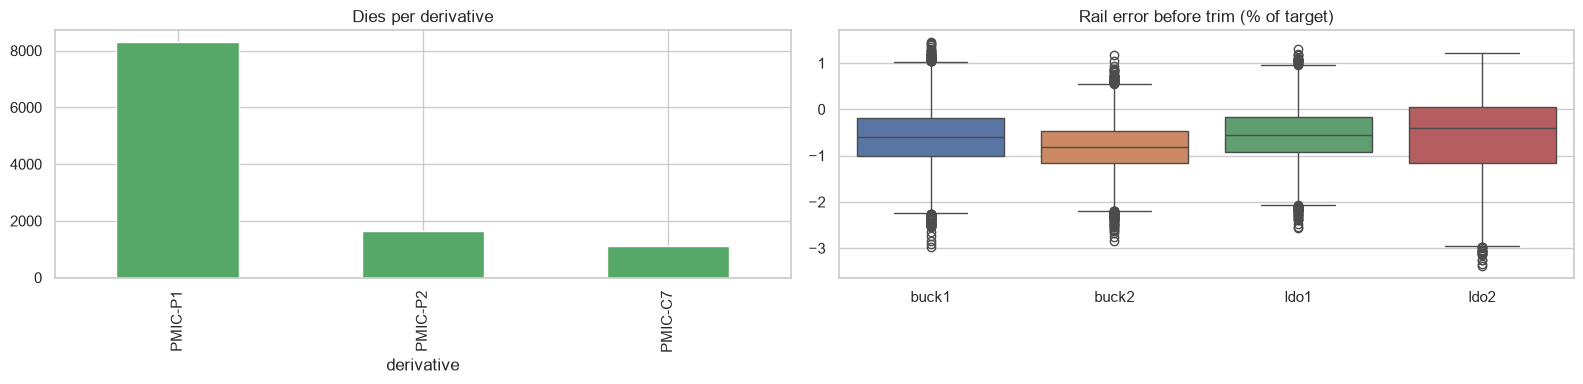

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
pmic.derivative.value_counts().plot.bar(ax=ax[0], title="Dies per derivative", color="#55a868")
err = pd.DataFrame({r: (pmic[f"{r}_untrim_V"] / pmic[f"{r}_target_V"] - 1) * 100 for r in RAILS})
sns.boxplot(data=err, ax=ax[1]); ax[1].set_title("Rail error before trim (% of target)")
plt.tight_layout(); plt.show()

## 4.4 EDA: the trim codes, and how strongly the rails are coupled
All rails share the trimmed reference, so their codes are related. This is the "coupled multi-rail trim" idea from the brief.

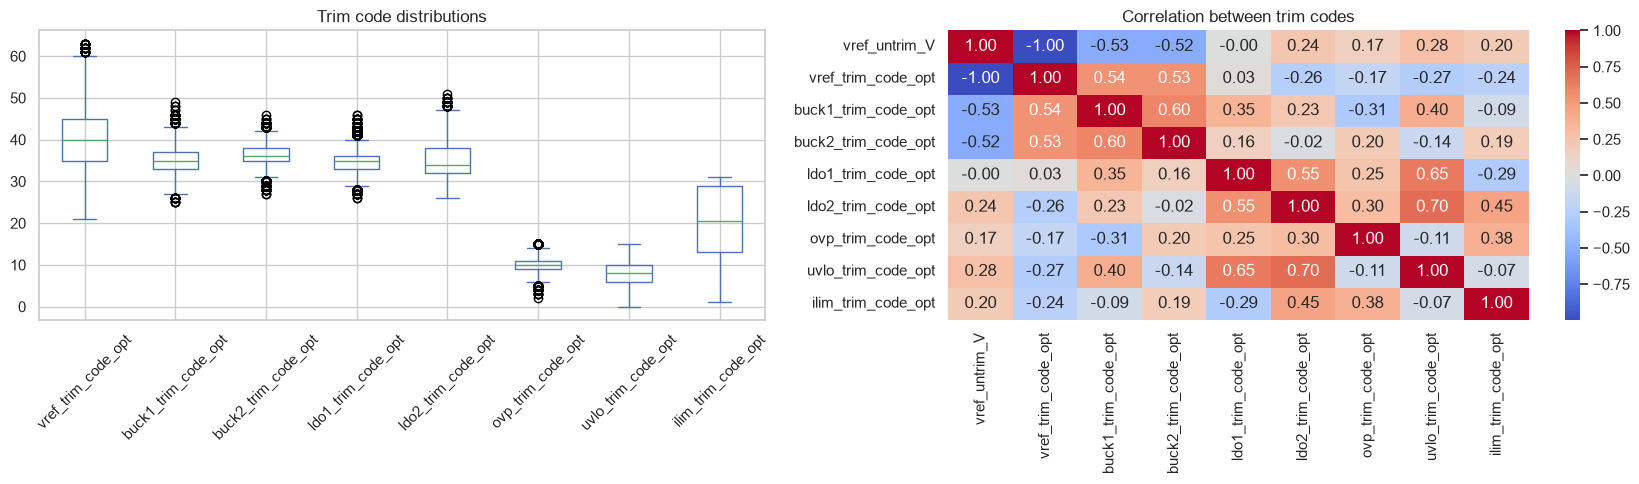

In [19]:
codes = ["vref_trim_code_opt"] + [f"{r}_trim_code_opt" for r in RAILS] + ["ovp_trim_code_opt", "uvlo_trim_code_opt", "ilim_trim_code_opt"]
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
pmic[codes].plot.box(ax=ax[0], rot=45, title="Trim code distributions")
sns.heatmap(pmic[["vref_untrim_V"] + codes].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Correlation between trim codes")
plt.tight_layout(); plt.show()

## 4.5 EDA: wafer map, efficiency and pass rates
Latent defects are highlighted in red on the efficiency vs. load-regulation chart. Outliers here are what an anomaly screen should flag.

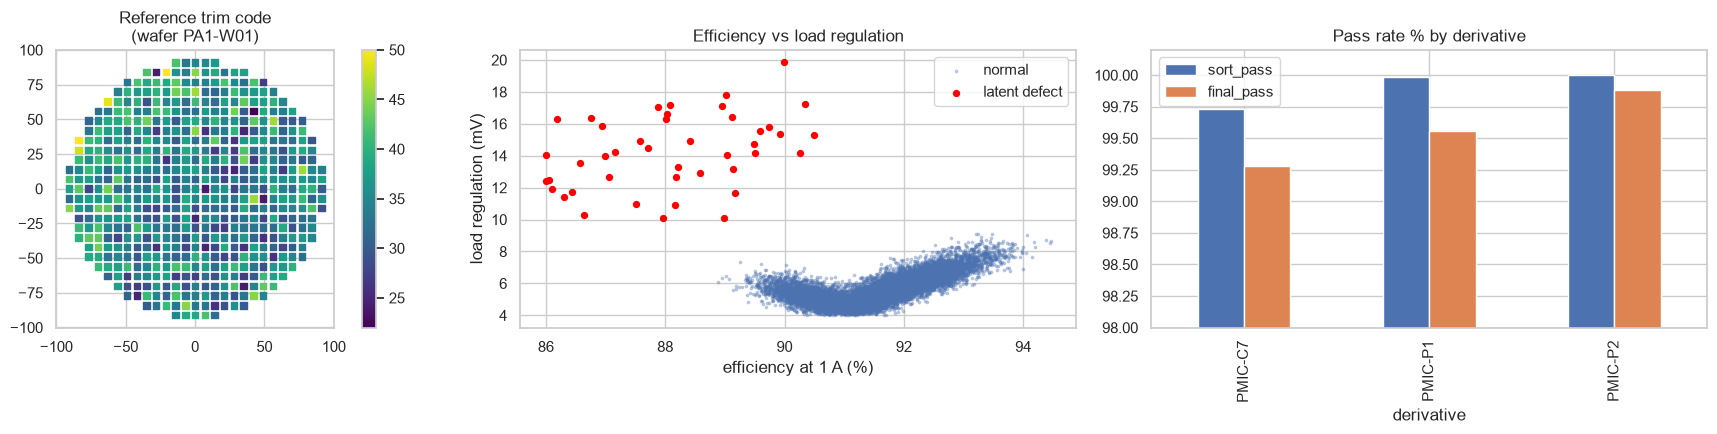

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
wafer_map(pmic, "vref_trim_code_opt", "Reference trim code", ax[0])
ax[1].scatter(pmic.efficiency_1A_pct, pmic.load_reg_mV, s=3, alpha=0.3, label="normal")
d = pmic[pmic.latent_defect]
ax[1].scatter(d.efficiency_1A_pct, d.load_reg_mV, s=18, color="red", label="latent defect")
ax[1].set(xlabel="efficiency at 1 A (%)", ylabel="load regulation (mV)", title="Efficiency vs load regulation"); ax[1].legend()
(pmic.groupby("derivative", observed=True)[["sort_pass", "final_pass"]].mean() * 100).plot.bar(
    ax=ax[2], ylim=(98, 100.2), title="Pass rate % by derivative")
plt.tight_layout(); plt.show()

---
# 5. `pmic_otp_config_requests.csv`: customer OTP requests
400 customer requests for default rail voltages, power-up sequence and I²C address. The `label` says whether each request is valid or which rule it breaks.

## 5.1 Preview and quality check

In [21]:
req = raw["otp_req"].copy()
quality_check(req, "pmic_otp_config_requests", "request_id")
req.head()

===== pmic_otp_config_requests =====
Rows: 400 | Columns: 10
Column types: {'numeric': 4, 'boolean': 0, 'text': 6}
Missing values: none
Duplicate rows: 0
Duplicate request_id: 0
Text columns: ['request_id', 'customer', 'sequence', 'i2c_addr', 'other_addresses_on_bus', 'label']


,request_id,customer,buck1_V,buck2_V,ldo1_V,ldo2_V,sequence,i2c_addr,other_addresses_on_bus,label
0,OTPREQ-0000,CUST-32,0.762,1.108,3.0,3.3,ldo1>buck1>buck2>ldo2,0x7F,0x3B;0x5E;0x70,address_reserved
1,OTPREQ-0001,CUST-04,0.650,1.051,2.8,3.3,buck1>buck2>ldo1>ldo2,0x60,0x36;0x3A;0x69,valid
2,OTPREQ-0002,CUST-02,0.785,1.072,3.0,3.3,buck2>ldo1>buck1>ldo2,0x49,0x43;0x61;0x77,valid
3,OTPREQ-0003,CUST-08,0.300,1.297,2.8,3.3,buck1>buck2>ldo2>ldo1,0x47,0x42;0x4A;0x55,out_of_range
4,OTPREQ-0004,CUST-33,1.061,1.195,2.8,3.3,ldo1>buck2>buck1>ldo2,0x52,0x30;0x40;0x69,valid


## 5.2 Is cleaning needed?
No missing values. **Needed:** the text fields must become numbers or flags before any rule or model can use them:
- `i2c_addr` → number; a flag for reserved I²C addresses (0x00 to 0x07 and 0x78 to 0x7F)
- `other_addresses_on_bus` ("0x3B;0x5E") → list; a flag if our address is already on the bus (a collision)
- `sequence` → a flag for a rail repeated or missing, and the position of each rail
- the rail voltages → a flag when any rail is outside its allowed range (device limits: buck 0.4–1.8 V, LDO1 0.8–3.3 V, LDO2 1.2–3.6 V)

In [22]:
req["i2c_addr_int"] = req.i2c_addr.apply(lambda h: int(h, 16))
req["bus_list"] = req.other_addresses_on_bus.fillna("").apply(lambda s: [int(a, 16) for a in s.split(";") if a])
req["n_bus_devices"] = req.bus_list.apply(len)
req["addr_reserved"] = (req.i2c_addr_int <= 0x07) | (req.i2c_addr_int >= 0x78)
req["addr_collision"] = req.apply(lambda r: r.i2c_addr_int in r.bus_list, axis=1)
steps = req.sequence.str.split(">")
req["seq_has_all_4"] = steps.apply(lambda s: sorted(s) == sorted(RAILS))
for r in RAILS:
    req[f"seq_pos_{r}"] = steps.apply(lambda s: s.index(r) + 1 if r in s else np.nan)
LIMITS = {"buck1": (0.4, 1.8), "buck2": (0.4, 1.8), "ldo1": (0.8, 3.3), "ldo2": (1.2, 3.6)}
req["voltage_out_of_range"] = np.any([~req[f"{r}_V"].between(*LIMITS[r]) for r in RAILS], axis=0)
clean.append("otp_req")
req[["request_id", "i2c_addr", "addr_reserved", "addr_collision", "sequence", "seq_has_all_4", "label"]].head()

,request_id,i2c_addr,addr_reserved,addr_collision,sequence,seq_has_all_4,label
0,OTPREQ-0000,0x7F,True,False,ldo1>buck1>buck2>ldo2,True,address_reserved
1,OTPREQ-0001,0x60,False,False,buck1>buck2>ldo1>ldo2,True,valid
2,OTPREQ-0002,0x49,False,False,buck2>ldo1>buck1>ldo2,True,valid
3,OTPREQ-0003,0x47,False,False,buck1>buck2>ldo2>ldo1,True,out_of_range
4,OTPREQ-0004,0x52,False,False,ldo1>buck2>buck1>ldo2,True,valid


## 5.3 EDA: label balance and requested voltages
60% of requests are valid. Each invalid type is fairly rare, so the classes are imbalanced.

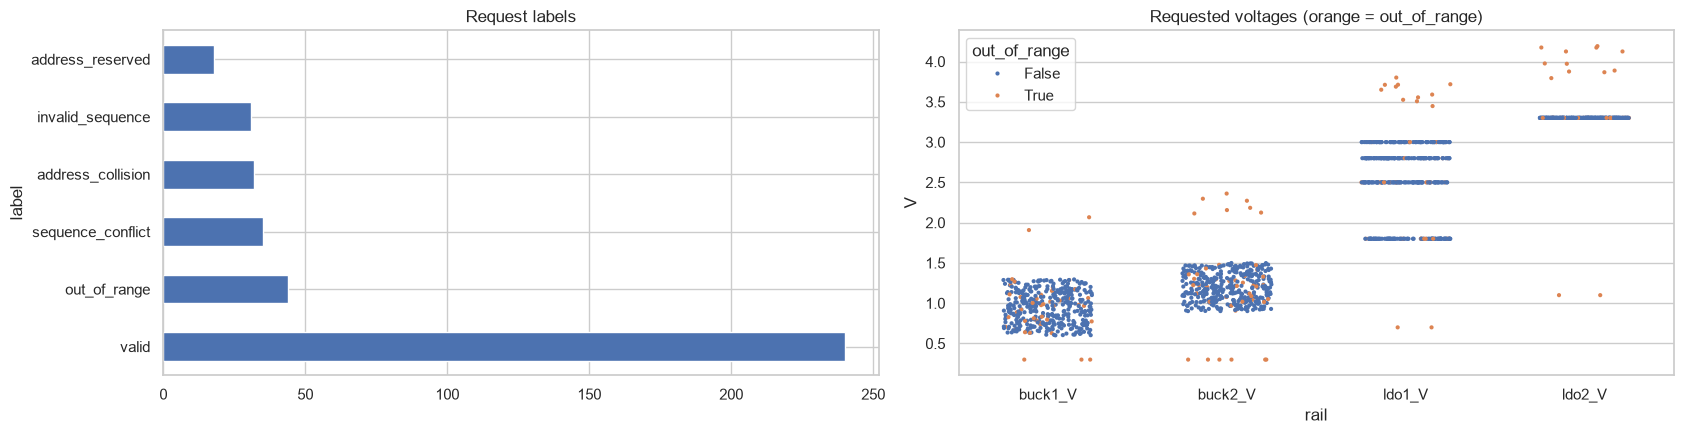

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
req.label.value_counts().plot.barh(ax=ax[0], title="Request labels")
long = req.melt(id_vars="label", value_vars=[f"{r}_V" for r in RAILS], var_name="rail", value_name="V")
sns.stripplot(data=long, x="rail", y="V", hue=long.label == "out_of_range", ax=ax[1], size=3, jitter=0.25)
ax[1].set_title("Requested voltages (orange = out_of_range)"); ax[1].legend(title="out_of_range")
plt.tight_layout(); plt.show()

## 5.4 EDA: do the simple flags explain the labels?
If each label lines up with one flag, a rule checker will work (built in notebook 02).

In [24]:
flags = req[["voltage_out_of_range", "addr_reserved", "addr_collision"]].assign(seq_incomplete=~req.seq_has_all_4,
                                                       ldo2_first=req.seq_pos_ldo2 == 1)
print((flags.groupby(req.label).mean() * 100).round(1).to_string())

                   voltage_out_of_range  addr_reserved  addr_collision  seq_incomplete  ldo2_first
label                                                                                             
address_collision                   0.0            0.0           100.0             0.0         0.0
address_reserved                    0.0          100.0             0.0             0.0         0.0
invalid_sequence                    0.0            0.0             0.0           100.0         6.5
out_of_range                      100.0            0.0             0.0             0.0         0.0
sequence_conflict                   0.0            0.0             0.0             0.0       100.0
valid                               0.0            0.0             0.0             0.0         0.0


---
# 6. `sensor_calibration.csv`: accelerometer calibration
Each row is one 3-axis accelerometer. Every die is measured at 25 °C. Only the `characterized_3temp` dies (20%) also have −40 °C and 85 °C data. The goal (notebook 03) is to predict the hot and cold behaviour from 25 °C data.

## 6.1 Preview and quality check

In [25]:
sensor = raw["sensor"].copy()
quality_check(sensor, "sensor_calibration", "die_id")
sensor.head(3)

===== sensor_calibration =====
Rows: 11,060 | Columns: 67
Column types: {'numeric': 60, 'boolean': 2, 'text': 5}
Missing values: none
Duplicate rows: 0
Duplicate die_id: 0
Text columns: ['die_id', 'lot_id', 'wafer_id', 'derivative', 'package']


,die_id,lot_id,wafer_id,derivative,die_x,die_y,x_mm,y_mm,radius_mm,pcm_vth_n_mV,pcm_vth_p_mV,pcm_rs_ohm_sq,pcm_tox_A,pcm_mobility_rel,full_scale_g,nominal_sens_LSB_per_g,package,latent_defect,stress_gauge_mV,asic_vref_mV,mems_resonance_kHz,mems_q_factor,characterized_3temp,st_response_x_mg,offset_x_m40C_mg,sens_x_m40C_rel,offset_x_25C_mg,sens_x_25C_rel,offset_x_85C_mg,sens_x_85C_rel,tco_x_true_mg_per_C,tco2_x_true_mg_per_C2,tcs_x_true_ppm_per_C,post_reflow_offset_shift_x_mg,cal_offset_code_x,cal_tco_code_x,cal_tcs_code_x,st_response_y_mg,offset_y_m40C_mg,sens_y_m40C_rel,offset_y_25C_mg,sens_y_25C_rel,offset_y_85C_mg,sens_y_85C_rel,tco_y_true_mg_per_C,tco2_y_true_mg_per_C2,tcs_y_true_ppm_per_C,post_reflow_offset_shift_y_mg,cal_offset_code_y,cal_tco_code_y,cal_tcs_code_y,st_response_z_mg,offset_z_m40C_mg,sens_z_m40C_rel,offset_z_25C_mg,sens_z_25C_rel,offset_z_85C_mg,sens_z_85C_rel,tco_z_true_mg_per_C,tco2_z_true_mg_per_C2,tcs_z_true_ppm_per_C,post_reflow_offset_shift_z_mg,cal_offset_code_z,cal_tco_code_z,cal_tcs_code_z,conv_test_insertions,conv_test_time_s
0,SNS-000000,SA1,SA1-W01,ACC-2G,12,1,-14.0,-91.0,92.07,409.31,-458.02,288.99,20.434,1.0246,2,16384,LGA14,False,-0.414,1186.181,5.1240,2.0482,False,492.491,-36.389,0.992587,-28.055,0.978392,-16.489,0.967169,0.13861,0.000302,-195.281,1.030,58,-14,39,496.418,-33.170,1.008096,-25.501,0.989546,-21.438,0.971912,0.10770,-0.000211,-285.663,1.667,53,-11,57,486.367,-41.233,0.996447,-31.317,0.986123,-16.016,0.972623,0.20865,-0.000016,-194.090,1.842,60,-21,39,3,7.28
1,SNS-000001,SA1,SA1-W01,ACC-2G,13,1,-7.0,-91.0,91.27,412.32,-463.23,298.52,20.114,1.0047,2,16384,LGA14,False,6.261,1187.298,5.0216,2.0369,False,493.294,-38.813,1.004790,-23.705,0.998965,-13.979,0.992677,0.20488,0.000344,-92.231,2.078,54,-20,18,495.489,-19.768,0.998627,-17.177,0.983073,-11.139,0.971600,0.05540,-0.000023,-228.978,4.131,34,-6,46,510.306,-24.944,1.025262,-14.224,1.013889,-10.203,1.004900,0.12935,-0.000411,-186.461,4.881,32,-13,37,3,7.29
2,SNS-000002,SA1,SA1-W01,ACC-2G,14,1,0.0,-91.0,91.00,411.43,-456.92,289.08,20.023,0.9952,2,16384,LGA14,False,5.873,1185.973,5.0108,1.9688,False,500.081,-19.097,0.992508,-11.303,0.983206,-5.191,0.974022,0.12452,-0.000210,-147.958,1.950,21,-12,30,501.796,-25.935,1.007475,-11.353,0.993432,-1.095,0.983269,0.21952,-0.000591,-179.638,1.915,20,-22,36,483.426,-31.536,0.993544,-9.304,0.985804,5.983,0.979358,0.29020,0.000089,-119.060,4.747,19,-29,24,3,7.18


## 6.2 Is cleaning needed?
No missing values, no duplicates, and the only text columns are IDs and categories. **No cleaning needed.** We only set the category types.

In [26]:
for c in ["derivative", "package"]:
    sensor[c] = sensor[c].astype("category")
clean.append("sensor")
print(sensor.groupby("derivative", observed=True).agg(dies=("die_id", "count"), full_scale_g=("full_scale_g", "first"),
      characterized=("characterized_3temp", "mean")).round(3).to_string())

            dies  full_scale_g  characterized
derivative                                   
ACC-16G     1106            16          0.187
ACC-2G      8295             2          0.197
ACC-8G      1659             8          0.201


## 6.3 EDA: how offset and sensitivity change with temperature
The average offset and sensitivity of each axis at −40, 25 and 85 °C. The slope of these lines is the temperature coefficient (TCO / TCS) we want to predict.

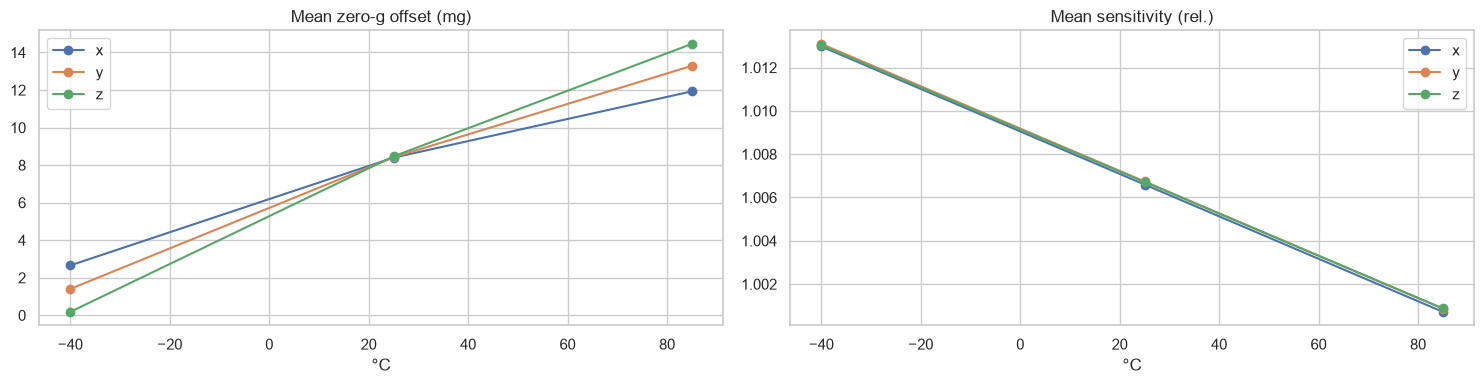

In [27]:
temps = [(-40, "m40C"), (25, "25C"), (85, "85C")]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for axis in "xyz":
    ax[0].plot([t for t, _ in temps], [sensor[f"offset_{axis}_{s}_mg"].mean() for _, s in temps], marker="o", label=axis)
    ax[1].plot([t for t, _ in temps], [sensor[f"sens_{axis}_{s}_rel"].mean() for _, s in temps], marker="o", label=axis)
ax[0].set(title="Mean zero-g offset (mg)", xlabel="°C"); ax[1].set(title="Mean sensitivity (rel.)", xlabel="°C")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

## 6.4 EDA: the targets and their link to 25 °C data
Left: spread of the X-axis temperature coefficients. Right: which 25 °C features correlate with them (useful predictors).

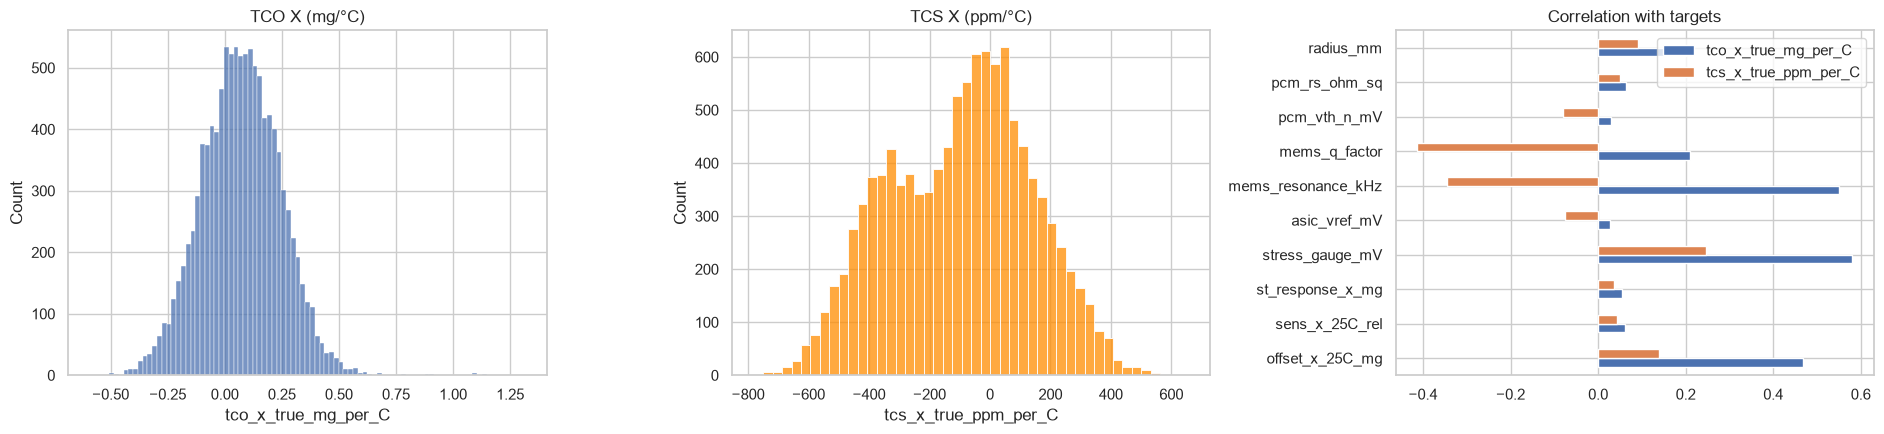

In [28]:
feats = ["offset_x_25C_mg", "sens_x_25C_rel", "st_response_x_mg", "stress_gauge_mV", "asic_vref_mV",
         "mems_resonance_kHz", "mems_q_factor", "pcm_vth_n_mV", "pcm_rs_ohm_sq", "radius_mm"]
fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
sns.histplot(sensor.tco_x_true_mg_per_C, ax=ax[0]); ax[0].set_title("TCO X (mg/°C)")
sns.histplot(sensor.tcs_x_true_ppm_per_C, ax=ax[1], color="darkorange"); ax[1].set_title("TCS X (ppm/°C)")
sensor[feats + ["tco_x_true_mg_per_C", "tcs_x_true_ppm_per_C"]].corr().loc[feats, ["tco_x_true_mg_per_C", "tcs_x_true_ppm_per_C"]].plot.barh(
    ax=ax[2], title="Correlation with targets")
plt.tight_layout(); plt.show()

## 6.5 EDA: package stress, post-reflow shift and today's test cost
Solder reflow shifts the offset, and the on-chip stress gauge predicts it. The conventional flow needs 3 temperature insertions.

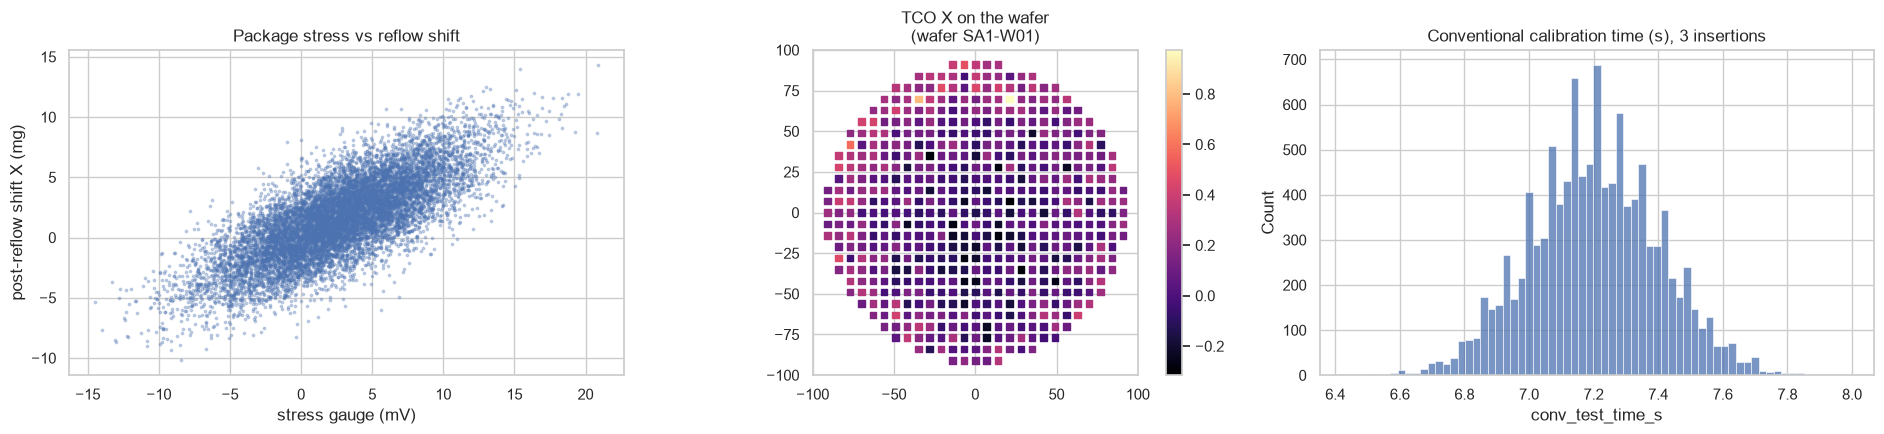

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
ax[0].scatter(sensor.stress_gauge_mV, sensor.post_reflow_offset_shift_x_mg, s=3, alpha=0.3)
ax[0].set(xlabel="stress gauge (mV)", ylabel="post-reflow shift X (mg)", title="Package stress vs reflow shift")
wafer_map(sensor, "tco_x_true_mg_per_C", "TCO X on the wafer", ax[1], cmap="magma")
sns.histplot(sensor.conv_test_time_s, ax=ax[2]); ax[2].set_title(
    f"Conventional calibration time (s), {sensor.conv_test_insertions.iloc[0]} insertions")
plt.tight_layout(); plt.show()

---
# 7. `soc_binning_harvesting.csv`: SoC binning and harvesting
Each row is one 8-core SoC die: on-chip monitors, each core's Fmax, Vmin and defect status, L2 cache fails, the AVS voltage bin, cores fused off, and the SKU it was sold as.

## 7.1 Preview and quality check

In [30]:
soc = raw["soc"].copy()
quality_check(soc, "soc_binning_harvesting", "die_id")
soc.head(3)

===== soc_binning_harvesting =====
Rows: 6,160 | Columns: 52
Column types: {'numeric': 37, 'boolean': 9, 'text': 6}
Missing values: 
                    missing    pct
core0_fmax_GHz          650  10.55
core0_vmin_2GHz_mV      650  10.55
core1_fmax_GHz          648  10.52
core1_vmin_2GHz_mV      648  10.52
core2_fmax_GHz          657  10.67
core2_vmin_2GHz_mV      657  10.67
core3_fmax_GHz          675  10.96
core3_vmin_2GHz_mV      675  10.96
core4_fmax_GHz          710  11.53
core4_vmin_2GHz_mV      710  11.53
core5_fmax_GHz          648  10.52
core5_vmin_2GHz_mV      648  10.52
core6_fmax_GHz          653  10.60
core6_vmin_2GHz_mV      653  10.60
core7_fmax_GHz          677  10.99
core7_vmin_2GHz_mV      677  10.99
avs_voltage_V            16   0.26
power_at_sku_W           16   0.26
Duplicate rows: 0
Duplicate die_id: 0
Text columns: ['die_id', 'lot_id', 'wafer_id', 'derivative', 'sku_rule_based', 'cores_disabled_mask']


,die_id,lot_id,wafer_id,derivative,die_x,die_y,x_mm,y_mm,radius_mm,pcm_vth_n_mV,pcm_vth_p_mV,pcm_rs_ohm_sq,pcm_tox_A,pcm_mobility_rel,ro_freq_MHz,cpm_path_delay_ps,iddq_25C_mA,core0_defect,core0_fmax_GHz,core0_vmin_2GHz_mV,core1_defect,core1_fmax_GHz,core1_vmin_2GHz_mV,core2_defect,core2_fmax_GHz,core2_vmin_2GHz_mV,core3_defect,core3_fmax_GHz,core3_vmin_2GHz_mV,core4_defect,core4_fmax_GHz,core4_vmin_2GHz_mV,core5_defect,core5_fmax_GHz,core5_vmin_2GHz_mV,core6_defect,core6_fmax_GHz,core6_vmin_2GHz_mV,core7_defect,core7_fmax_GHz,core7_vmin_2GHz_mV,l2_slice0_fail_bits,l2_slice1_fail_bits,l2_slice2_fail_bits,l2_slice3_fail_bits,l2_repairable,conv_speed_test_time_ms,sku_rule_based,avs_voltage_bin,avs_voltage_V,cores_disabled_mask,power_at_sku_W
0,SOC-000000,QA1,QA1-W01,SoC-Std,8,1,-35.0,-133.0,137.53,454.14,-478.86,337.89,19.895,0.8532,865.77,347.77,99.62,False,2.6958,671.45,False,2.6816,669.31,False,2.6922,666.44,False,2.6921,661.34,True,NaN,NaN,False,2.6411,673.15,False,2.7195,670.41,False,2.7388,675.30,1,3,0,1,True,485.3,SoC-Std,7,0.8375,0x30,11.225
1,SOC-000001,QA1,QA1-W01,SoC-Std,9,1,-21.0,-133.0,134.65,461.28,-486.14,333.33,20.018,0.8766,850.38,351.16,95.66,False,2.6693,690.33,True,NaN,NaN,False,2.6736,663.59,True,NaN,NaN,False,2.6610,670.50,False,2.7287,672.25,False,2.6690,687.50,False,2.5688,672.66,0,1,3,2,True,511.4,SoC-Std,9,0.8625,0x0A,11.774
2,SOC-000002,QA1,QA1-W01,SoC-Std,10,1,-7.0,-133.0,133.18,454.06,-492.79,335.63,20.313,0.8895,877.94,346.82,124.11,False,2.7717,670.09,False,2.6866,670.13,False,2.7062,667.91,False,2.7180,659.04,False,2.7172,679.01,False,2.7524,679.07,False,2.7652,675.19,False,2.6979,677.59,1,1,3,3,True,456.2,SoC-Std,6,0.8250,0x82,11.364


## 7.2 Are the missing values a problem?
About 10% of each core's `fmax` and `vmin` are blank. Check: are they blank **exactly** where the core is defective? If so, the blank is correct (a dead core has no speed) and must **not** be filled with an average.

In [31]:
rows = []
for i in range(8):
    blank, bad = soc[f"core{i}_fmax_GHz"].isna(), soc[f"core{i}_defect"]
    rows.append({"core": i, "defective": int(bad.sum()), "blank_fmax": int(blank.sum()),
                 "blank_but_good": int((blank & ~bad).sum()), "defective_but_filled": int((bad & ~blank).sum())})
print(pd.DataFrame(rows).to_string(index=False))
scrap = soc.sku_rule_based == "scrap"
print("\nBlank avs_voltage_V / power only on scrap dies:", soc.avs_voltage_V.isna().equals(scrap))

 core  defective  blank_fmax  blank_but_good  defective_but_filled
    0        650         650               0                     0
    1        648         648               0                     0
    2        657         657               0                     0
    3        675         675               0                     0
    4        710         710               0                     0
    5        648         648               0                     0
    6        653         653               0                     0
    7        677         677               0                     0

Blank avs_voltage_V / power only on scrap dies: True


## 7.3 Cleaning
The blanks are correct, so **no imputation**. **Needed:**
- `cores_disabled_mask` (hex text) → a number and a count of disabled cores
- new summary columns: number of defective cores, slowest good core's Fmax (`fmax_min_good`), highest Vmin

In [32]:
fcols, vcols = [f"core{i}_fmax_GHz" for i in range(8)], [f"core{i}_vmin_2GHz_mV" for i in range(8)]
soc["cores_disabled_int"] = soc.cores_disabled_mask.apply(lambda h: int(h, 16))
soc["n_cores_disabled"] = soc.cores_disabled_int.apply(lambda m: bin(m).count("1"))
soc["n_defective_cores"] = soc[[f"core{i}_defect" for i in range(8)]].sum(axis=1)
soc["fmax_min_good"] = soc[fcols].min(axis=1)
soc["vmin_max_good"] = soc[vcols].max(axis=1)
soc["sku_rule_based"] = soc.sku_rule_based.astype("category")
clean.append("soc")
soc[["die_id", "cores_disabled_mask", "n_cores_disabled", "n_defective_cores", "fmax_min_good", "sku_rule_based"]].head()

,die_id,cores_disabled_mask,n_cores_disabled,n_defective_cores,fmax_min_good,sku_rule_based
0,SOC-000000,0x30,2,1,2.6411,SoC-Std
1,SOC-000001,0x0A,2,2,2.5688,SoC-Std
2,SOC-000002,0x82,2,0,2.6866,SoC-Std
3,SOC-000003,0x28,2,1,2.7474,SoC-Std
4,SOC-000004,0x42,2,1,2.6451,SoC-Std


## 7.4 EDA: SKU mix and defective cores

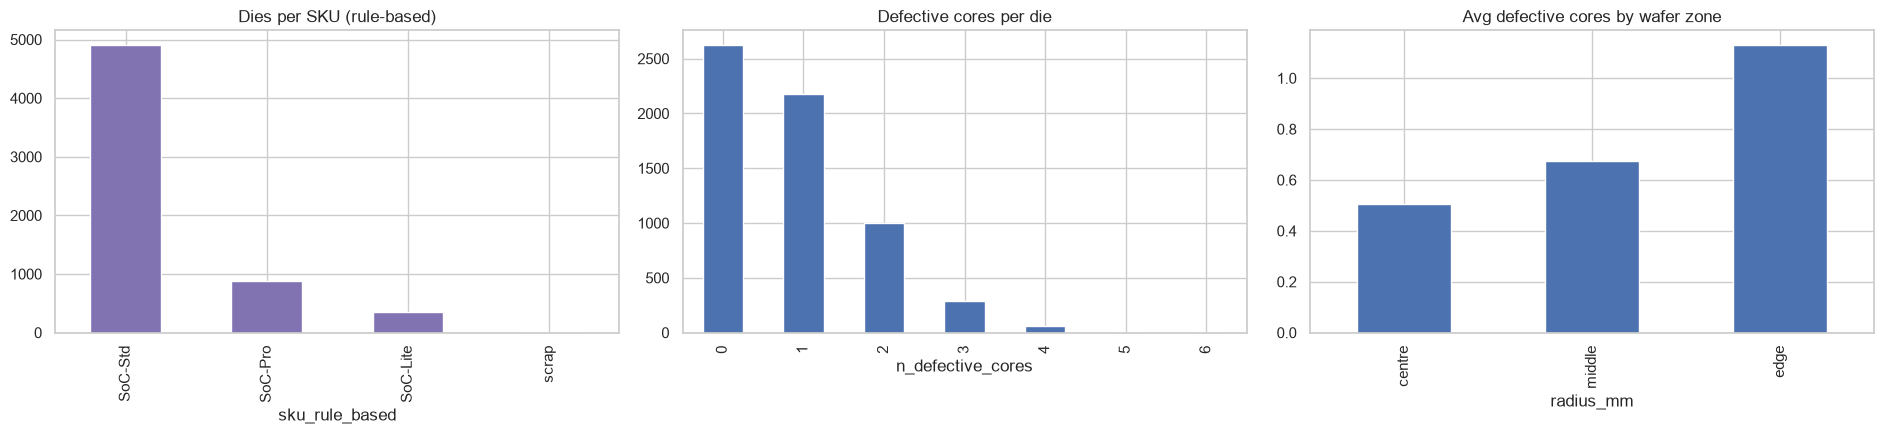

In [33]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
soc.sku_rule_based.value_counts().plot.bar(ax=ax[0], title="Dies per SKU (rule-based)", color="#8172b2")
soc.n_defective_cores.value_counts().sort_index().plot.bar(ax=ax[1], title="Defective cores per die")
zone = pd.cut(soc.radius_mm, [0, 50, 100, 200], labels=["centre", "middle", "edge"])
(soc.groupby(zone, observed=True).n_defective_cores.mean()).plot.bar(ax=ax[2], title="Avg defective cores by wafer zone")
plt.tight_layout(); plt.show()

## 7.5 EDA: do the monitors predict speed?
If the ring oscillator and critical-path monitor track the slowest core's Fmax, notebook 04 can predict speed without long functional tests.

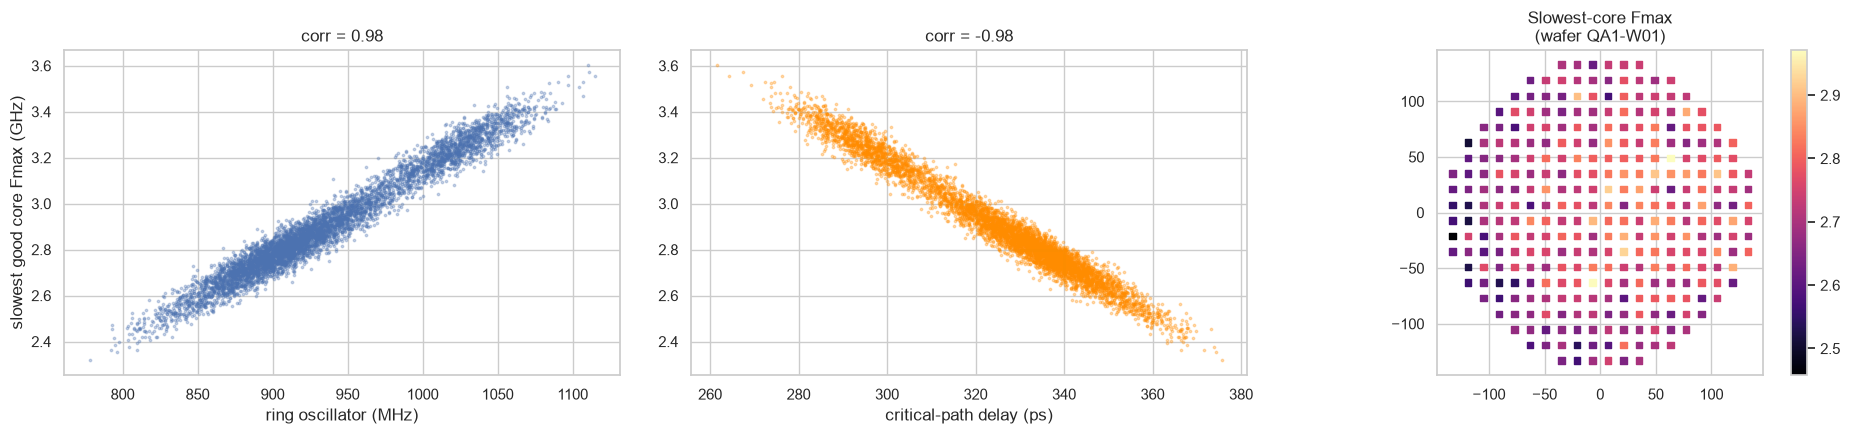

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
ax[0].scatter(soc.ro_freq_MHz, soc.fmax_min_good, s=3, alpha=0.3)
ax[0].set(xlabel="ring oscillator (MHz)", ylabel="slowest good core Fmax (GHz)",
          title=f"corr = {soc.ro_freq_MHz.corr(soc.fmax_min_good):.2f}")
ax[1].scatter(soc.cpm_path_delay_ps, soc.fmax_min_good, s=3, alpha=0.3, color="darkorange")
ax[1].set(xlabel="critical-path delay (ps)", title=f"corr = {soc.cpm_path_delay_ps.corr(soc.fmax_min_good):.2f}")
wafer_map(soc, "fmax_min_good", "Slowest-core Fmax", ax[2], cmap="magma")
plt.tight_layout(); plt.show()

## 7.6 EDA: AVS voltage bins and power per SKU

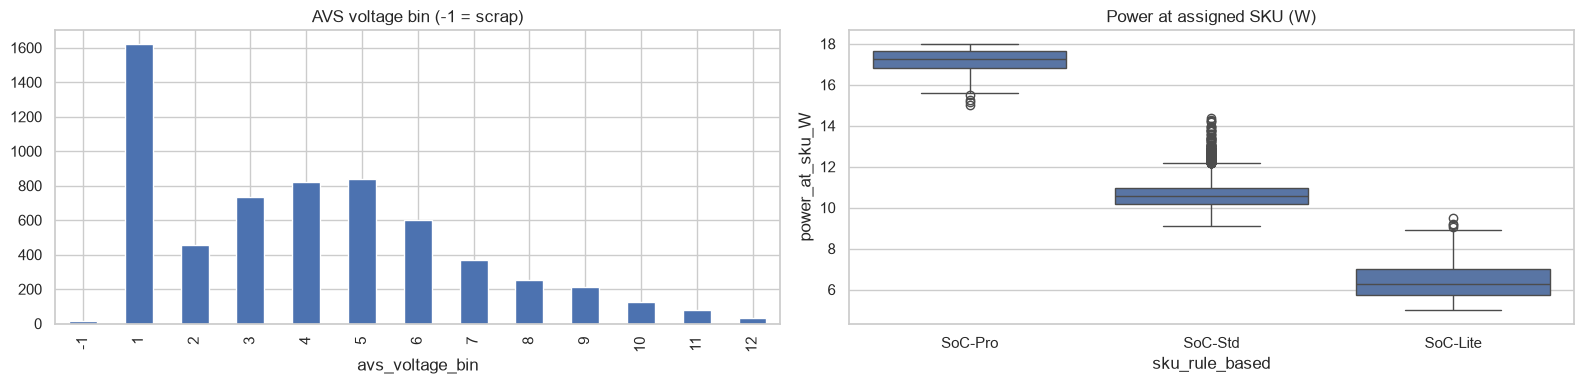

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
soc.avs_voltage_bin.value_counts().sort_index().plot.bar(ax=ax[0], title="AVS voltage bin (-1 = scrap)")
sns.boxplot(data=soc[~scrap], x="sku_rule_based", y="power_at_sku_W", ax=ax[1],
            order=["SoC-Pro", "SoC-Std", "SoC-Lite"])
ax[1].set_title("Power at assigned SKU (W)")
plt.tight_layout(); plt.show()

---
# 8. `soc_sku_demand.csv`: SKU prices and demand (reference table)
Only 3 rows, so no statistical EDA. Instead we compare what the fab **produces** (rule-based SKU mix from dataset 7) with what customers **want** (demand). That gap is why notebook 04 optimizes the die-to-SKU assignment.

In [36]:
sku = raw["sku"].copy()
quality_check(sku, "soc_sku_demand")
sku

===== soc_sku_demand =====
Rows: 3 | Columns: 6
Column types: {'numeric': 5, 'boolean': 0, 'text': 1}
Missing values: none
Duplicate rows: 0
Text columns: ['sku']


,sku,cores,fmax_GHz,tdp_W,price_usd,weekly_demand_units
0,SoC-Pro,8,3.0,18.0,145,900
1,SoC-Std,6,2.6,15.0,95,2200
2,SoC-Lite,4,2.2,10.0,55,2600


## 8.1 Is cleaning needed?
No: 3 clean rows, all numeric except the SKU name.

          price_usd  weekly_demand_units  demand_share  supply_share  revenue_per_100_dies
sku                                                                                       
SoC-Pro         145                  900         0.158         0.144              2085.552
SoC-Std          95                 2200         0.386         0.797              7570.698
SoC-Lite         55                 2600         0.456         0.057               311.607


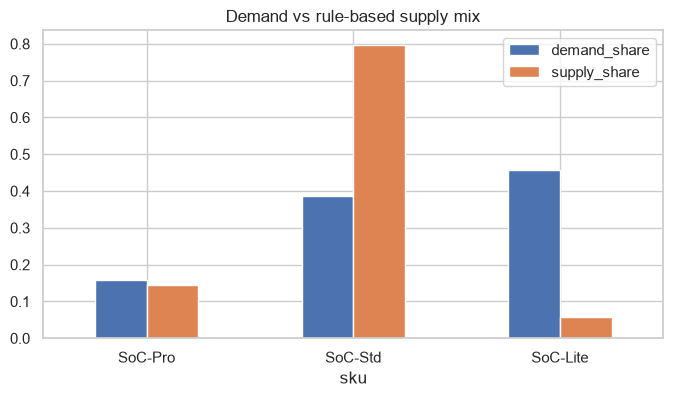

In [37]:
clean.append("sku")
supply = soc.sku_rule_based.value_counts(normalize=True).rename("supply_share")
mix = sku.set_index("sku").join(supply)
mix["demand_share"] = mix.weekly_demand_units / mix.weekly_demand_units.sum()
mix["revenue_per_100_dies"] = mix.supply_share * 100 * mix.price_usd
print(mix[["price_usd", "weekly_demand_units", "demand_share", "supply_share", "revenue_per_100_dies"]].round(3).to_string())
mix[["demand_share", "supply_share"]].plot.bar(figsize=(8, 4), title="Demand vs rule-based supply mix", rot=0); plt.show()

---
# 9. `memory_repair_bitmaps.csv`: memory repair
Each row is one 512×512 L2 cache array with up to 4 spare rows and 4 spare columns. `fail_cells` lists the broken cells. The question: can the spares cover every fail? It is answered two ways, greedy and exact.

## 9.1 Preview and quality check

In [38]:
repair = raw["repair"].copy()
quality_check(repair, "memory_repair_bitmaps", "array_id")
print("All dies exist in soc_binning_harvesting:", repair.die_id.isin(soc.die_id).all())
repair.head(3)

===== memory_repair_bitmaps =====
Rows: 3,000 | Columns: 13
Column types: {'numeric': 5, 'boolean': 2, 'text': 6}
Missing values: 
                         missing    pct
fail_cells                   167   5.57
optimal_spare_rows_used     1354  45.13
optimal_spare_cols_used     2005  66.83
Duplicate rows: 0
Duplicate array_id: 0
Text columns: ['array_id', 'die_id', 'array', 'fail_cells', 'optimal_spare_rows_used', 'optimal_spare_cols_used']


All dies exist in soc_binning_harvesting: True


,array_id,die_id,array,rows,cols,spare_rows,spare_cols,n_fail_cells,fail_cells,greedy_repairable,optimal_repairable,optimal_spare_rows_used,optimal_spare_cols_used
0,L2ARR-00000,SOC-005713,L2_slice0,512,512,4,4,20,5:334;31:204;49:173;56:204;74:204;95:204;130:2...,True,True,5;49;292;468,204
1,L2ARR-00001,SOC-002709,L2_slice0,512,512,4,4,50,31:60;34:60;44:60;52:60;59:223;77:223;89:223;9...,True,True,334;380,60;223
2,L2ARR-00002,SOC-003220,L2_slice0,512,512,4,4,38,0:91;0:189;0:251;0:315;0:379;0:401;0:457;0:475...,True,True,0;76;134;225,206


## 9.2 Are the missing values a problem?
Checks that:
- `fail_cells` is blank only when there are 0 fails
- the spare lists are blank only when the array is unrepairable, or when no spare of that kind was needed

In [39]:
print("fail_cells blank  <=> n_fail_cells == 0 :", repair.fail_cells.isna().equals(repair.n_fail_cells == 0))
rows_blank = repair.optimal_spare_rows_used.isna()
print("Unrepairable arrays with blank spare lists:", int((rows_blank & ~repair.optimal_repairable).sum()),
      "of", int((~repair.optimal_repairable).sum()))
print("Repairable arrays that used no spare rows :", int((rows_blank & repair.optimal_repairable).sum()))

fail_cells blank  <=> n_fail_cells == 0 : True
Unrepairable arrays with blank spare lists: 1140 of 1140
Repairable arrays that used no spare rows : 214


## 9.3 Cleaning
The blanks are meaningful (no fails, or no spares used), so they become empty lists, not averages. **Needed:** turn the `"row:col;row:col"` text into numbers and useful summary features:
- distinct failing rows and columns
- the most fails in any single row or column (a full row of fails is a cheap fix with one spare row)
- spare rows and columns used

In [40]:
def parse_cells(s):
    return [] if pd.isna(s) else [tuple(map(int, c.split(":"))) for c in s.split(";")]

cells = repair.fail_cells.apply(parse_cells)
print("Parsed count matches n_fail_cells:", (cells.apply(len) == repair.n_fail_cells).all())
repair["n_fail_rows"] = cells.apply(lambda c: len({r for r, _ in c}))
repair["n_fail_cols"] = cells.apply(lambda c: len({k for _, k in c}))
repair["max_fails_one_row"] = cells.apply(lambda c: pd.Series([r for r, _ in c]).value_counts().max() if c else 0)
repair["max_fails_one_col"] = cells.apply(lambda c: pd.Series([k for _, k in c]).value_counts().max() if c else 0)
count = lambda s: 0 if pd.isna(s) or s == "" else len(str(s).split(";"))
repair["spare_rows_used"] = repair.optimal_spare_rows_used.apply(count)
repair["spare_cols_used"] = repair.optimal_spare_cols_used.apply(count)
clean.append("repair")
repair[["array_id", "n_fail_cells", "n_fail_rows", "n_fail_cols", "max_fails_one_row", "max_fails_one_col",
        "greedy_repairable", "optimal_repairable"]].head()

Parsed count matches n_fail_cells: True


,array_id,n_fail_cells,n_fail_rows,n_fail_cols,max_fails_one_row,max_fails_one_col,greedy_repairable,optimal_repairable
0,L2ARR-00000,20,20,5,1,16,True,True
1,L2ARR-00001,50,49,4,2,27,True,True
2,L2ARR-00002,38,5,38,26,1,True,True
3,L2ARR-00003,12,2,12,11,1,True,True
4,L2ARR-00004,2,2,2,1,1,True,True


## 9.4 EDA: fail counts and greedy vs. exact repair
The exact solver repairs every array the greedy one does, plus some it misses. Those extra arrays are saved yield.

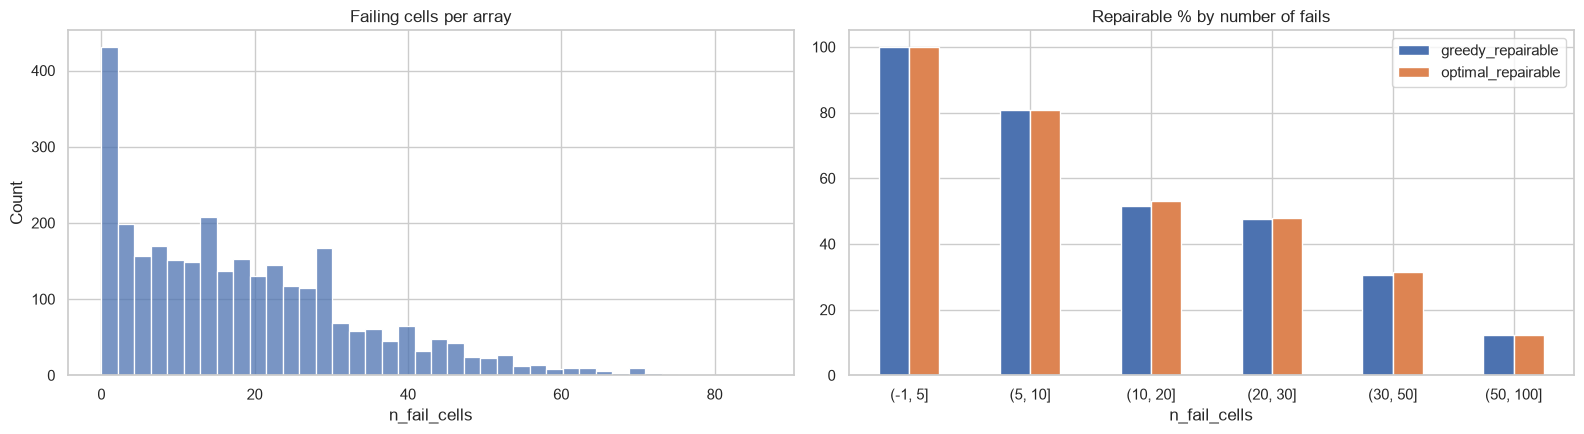

exact   False  True 
greedy              
False    1140     17
True        0   1843


In [41]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(repair.n_fail_cells, bins=40, ax=ax[0]); ax[0].set_title("Failing cells per array")
bins = pd.cut(repair.n_fail_cells, [-1, 5, 10, 20, 30, 50, 100])
repair.groupby(bins, observed=True)[["greedy_repairable", "optimal_repairable"]].mean().mul(100).plot.bar(
    ax=ax[1], title="Repairable % by number of fails", rot=0)
plt.tight_layout(); plt.show()
print(pd.crosstab(repair.greedy_repairable, repair.optimal_repairable, rownames=["greedy"], colnames=["exact"]))

## 9.5 EDA: one array that only the exact solver can repair
Red dots are failing cells. Blue lines are the spare rows and columns the exact solver chose.

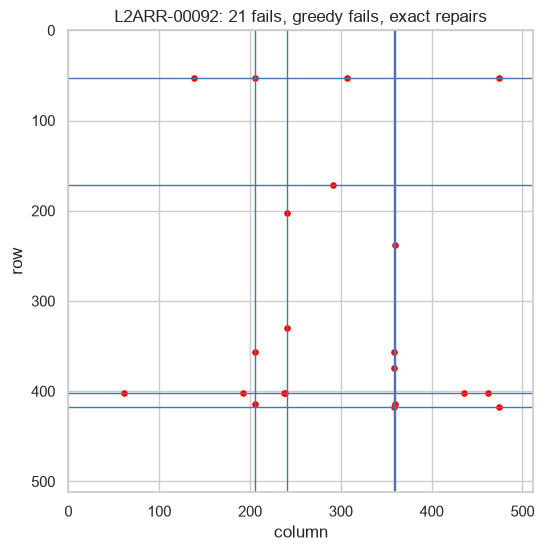

In [42]:
ex = repair[repair.optimal_repairable & ~repair.greedy_repairable].iloc[0]
pts = np.array(parse_cells(ex.fail_cells))
fig, ax = plt.subplots(figsize=(6, 6))
for r in str(ex.optimal_spare_rows_used).split(";"):
    if r not in ("", "nan"): ax.axhline(int(r), color="#4c72b0", lw=1)
for c in str(ex.optimal_spare_cols_used).split(";"):
    if c not in ("", "nan"): ax.axvline(int(c), color="#4c72b0", lw=1)
ax.scatter(pts[:, 1], pts[:, 0], color="red", s=14)
ax.set(xlim=(0, 512), ylim=(512, 0), xlabel="column", ylabel="row",
       title=f"{ex.array_id}: {ex.n_fail_cells} fails, greedy fails, exact repairs")
plt.show()

---
# 10. Save the cleaned datasets
Writes each cleaned table to a `cleaned/` folder. Notebooks 01 to 04 can load these directly. Columns that hold Python lists are dropped, because CSV cannot store them; the summary columns made from them are kept.

In [43]:
os.makedirs("cleaned", exist_ok=True)
tables = {"mcu": mcu, "schema": schema, "audit": audit, "pmic": pmic, "otp_req": req,
          "sensor": sensor, "soc": soc, "sku": sku, "repair": repair}
NAME = {v: k for k, v in SHORT.items()}
for k in clean:
    out = tables[k].drop(columns=[c for c in tables[k].columns if c == "bus_list"])
    path = f"cleaned/{NAME[k].replace('.csv', '_clean.csv')}"
    out.to_csv(path, index=False)
    print(f"{path:45s} {out.shape[0]:>6,} rows x {out.shape[1]:>3} cols (raw had {raw[k].shape[1]})")

cleaned/mcu_trim_fuse_clean.csv                8,420 rows x  44 cols (raw had 42)
cleaned/mcu_fuse_schema_clean.csv                 10 rows x  11 cols (raw had 7)
cleaned/mcu_fuse_map_audit_clean.csv           1,500 rows x  15 cols (raw had 5)


cleaned/pmic_trim_otp_clean.csv               11,060 rows x  68 cols (raw had 63)
cleaned/pmic_otp_config_requests_clean.csv       400 rows x  20 cols (raw had 10)


cleaned/sensor_calibration_clean.csv          11,060 rows x  67 cols (raw had 67)


cleaned/soc_binning_harvesting_clean.csv       6,160 rows x  57 cols (raw had 52)
cleaned/soc_sku_demand_clean.csv                   3 rows x   6 cols (raw had 6)
cleaned/memory_repair_bitmaps_clean.csv        3,000 rows x  19 cols (raw had 13)


# 11. Final summary of all 9 datasets

In [44]:
summary = pd.DataFrame([
    ["mcu_trim_fuse", "MCU", "bg/hsi/ldo_trim_code_opt", "clean", "decoded fuse word (matches codes)",
     "untrimmed reading drives codes; MCU-C final pass only 90.6% (drift)", "01"],
    ["mcu_fuse_schema", "MCU", "(reference)", "clean", "text values -> numbers", "10 fields over 64 bits; bits 43-63 reserved (must be 0)", "01"],
    ["mcu_fuse_map_audit", "MCU", "has_error / error_type", "clean", "decoded fields with schema",
     "each error type breaks exactly one rule", "01"],
    ["pmic_trim_otp", "PMIC", "rail & threshold trim codes", "clean", "I2C hex -> int, sequence -> positions",
     "buck codes correlate with the reference code (r about 0.5): coupled rails", "02"],
    ["pmic_otp_config_requests", "PMIC", "label", "clean", "addresses, bus list, sequence -> flags",
     "60% valid; one simple flag matches each error label", "02"],
    ["sensor_calibration", "Sensor", "TCO / TCS / hot-cold offsets", "clean", "none needed",
     "stress gauge and MEMS resonance relate to TCO (r about 0.55); stress predicts reflow shift (r 0.76)", "03"],
    ["soc_binning_harvesting", "SoC", "fmax / vmin / SKU", "blanks = defective cores (correct)",
     "mask hex -> int, summary columns", "monitors track slowest-core Fmax (|r| 0.98); edge dies have about 2x the defective cores", "04"],
    ["soc_sku_demand", "SoC", "(optimizer input)", "clean", "none needed", "Std oversupplied (80% vs 39% of demand), Lite undersupplied (6% vs 46%)", "04"],
    ["memory_repair_bitmaps", "SoC", "optimal_repairable", "blanks = no fails / no spares (correct)",
     "fail list -> row/col features", "exact solver repairs 17 arrays greedy misses", "04"],
], columns=["dataset", "chip", "target", "data quality", "cleaning done", "key EDA finding", "next notebook"])
summary

,dataset,chip,target,data quality,cleaning done,key EDA finding,next notebook
0,mcu_trim_fuse,MCU,bg/hsi/ldo_trim_code_opt,clean,decoded fuse word (matches codes),untrimmed reading drives codes; MCU-C final pa...,01
1,mcu_fuse_schema,MCU,(reference),clean,text values -> numbers,10 fields over 64 bits; bits 43-63 reserved (m...,01
2,mcu_fuse_map_audit,MCU,has_error / error_type,clean,decoded fields with schema,each error type breaks exactly one rule,01
3,pmic_trim_otp,PMIC,rail & threshold trim codes,clean,"I2C hex -> int, sequence -> positions",buck codes correlate with the reference code (...,02
4,pmic_otp_config_requests,PMIC,label,clean,"addresses, bus list, sequence -> flags",60% valid; one simple flag matches each error ...,02
5,sensor_calibration,Sensor,TCO / TCS / hot-cold offsets,clean,none needed,stress gauge and MEMS resonance relate to TCO ...,03
6,soc_binning_harvesting,SoC,fmax / vmin / SKU,blanks = defective cores (correct),"mask hex -> int, summary columns",monitors track slowest-core Fmax (|r| 0.98); e...,04
7,soc_sku_demand,SoC,(optimizer input),clean,none needed,"Std oversupplied (80% vs 39% of demand), Lite ...",04
8,memory_repair_bitmaps,SoC,optimal_repairable,blanks = no fails / no spares (correct),fail list -> row/col features,exact solver repairs 17 arrays greedy misses,04


## Conclusions
- **Data quality is good.** No duplicates in any file. The only blanks (SoC cores, memory repair) are **meaningful**: they mark defective cores and arrays with no fails, so they were kept, not filled.
- **The cleaning was mostly format conversion:** hex strings, power-up sequences, address lists and fail-cell lists were turned into numeric columns that rules and models can use.
- **Every invalid OTP request and every corrupted fuse word is explained by one simple rule**, so rule checkers (not ML) are the right first tool there.
- **The SoC fab output does not match demand:** too many Std dies and too few Lite. This is the business case for die-to-SKU optimization in notebook 04.
- **Consistency checks passed:** MCU fuse words match the trim codes, every audit die exists in the MCU data, and every repair array belongs to a SoC die.
- **Each dataset needs a different method:**
  - ML regression: MCU, PMIC and sensor trims; SoC Fmax
  - rule-based checks: fuse audit, OTP requests
  - optimization: SKU assignment, memory repair
- **Next:** notebooks 01 (MCU, done), 02 (PMIC), 03 (sensor) and 04 (SoC) load the files in `cleaned/`.